In [ ]:
#!pip install pandas matplotlib seaborn

Formato: (48712, 30)
id                        float64
data_inversa               object
dia_semana                 object
horario                    object
uf                         object
br                          int64
km                        float64
municipio                  object
causa_acidente             object
tipo_acidente              object
classificacao_acidente     object
fase_dia                   object
sentido_via                object
condicao_metereologica     object
tipo_pista                 object
tracado_via                object
uso_solo                   object
pessoas                     int64
mortos                      int64
feridos_leves               int64
feridos_graves              int64
ilesos                      int64
ignorados                   int64
feridos                     int64
veiculos                    int64
latitude                  float64
longitude                 float64
regional                   object
delegacia                  

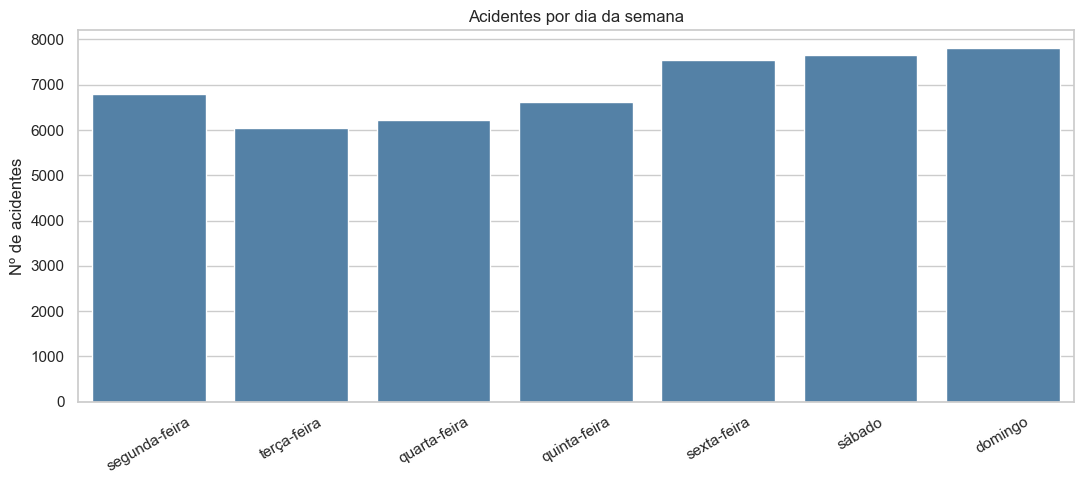

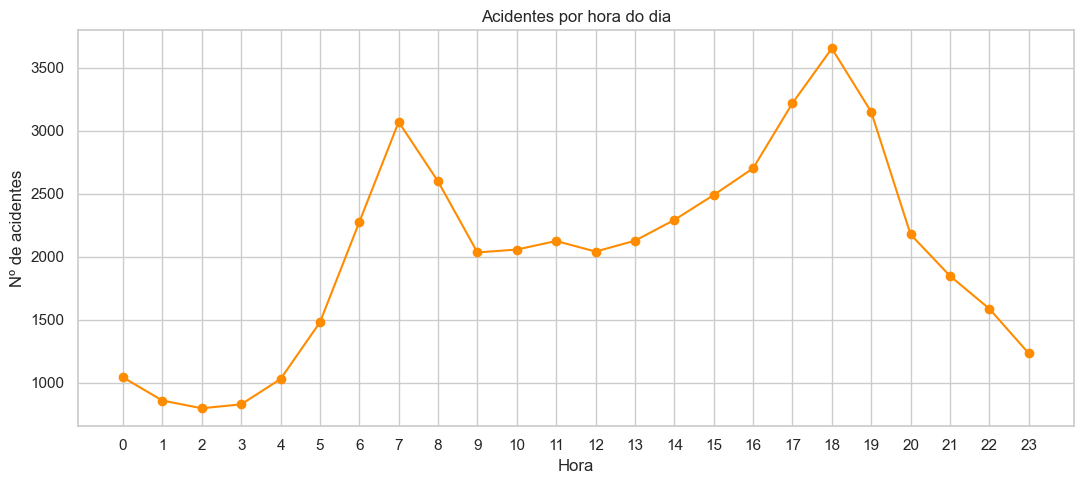

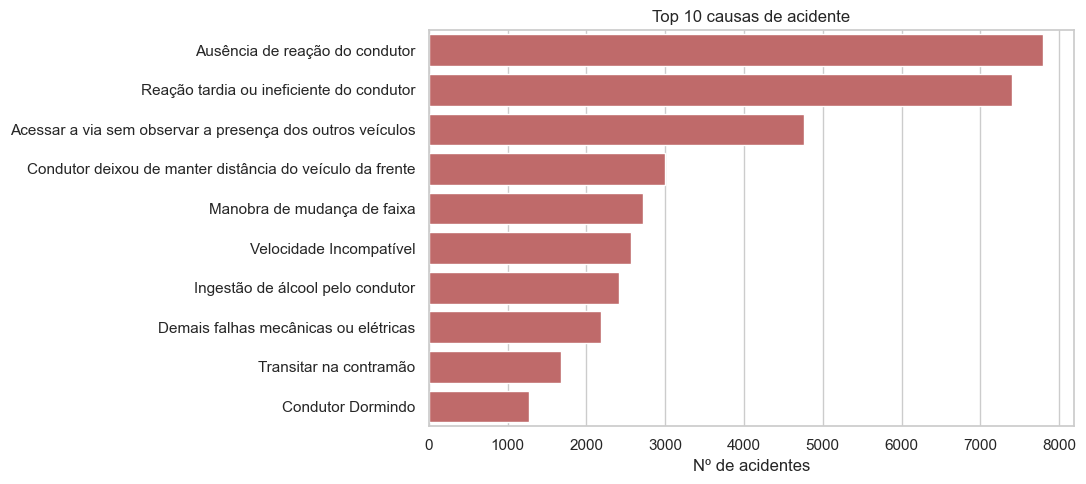

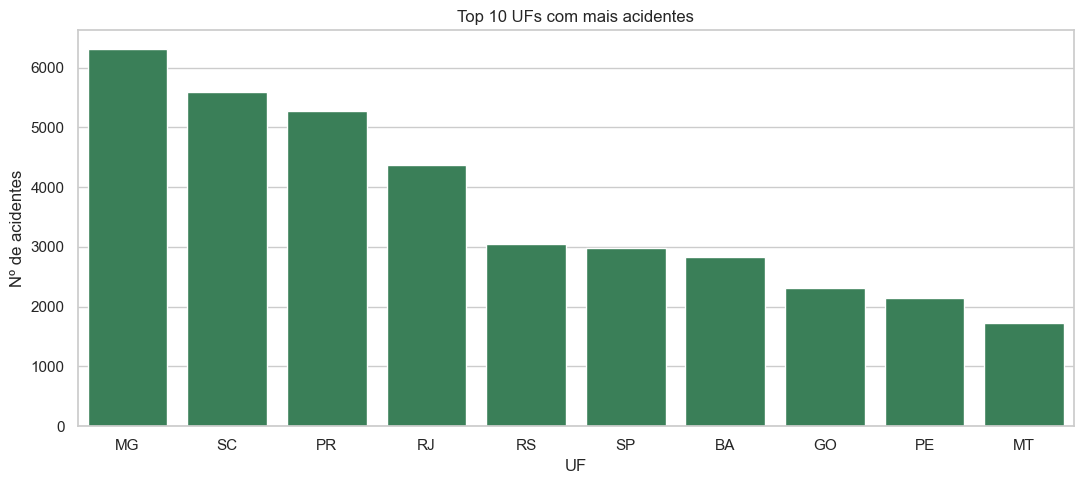

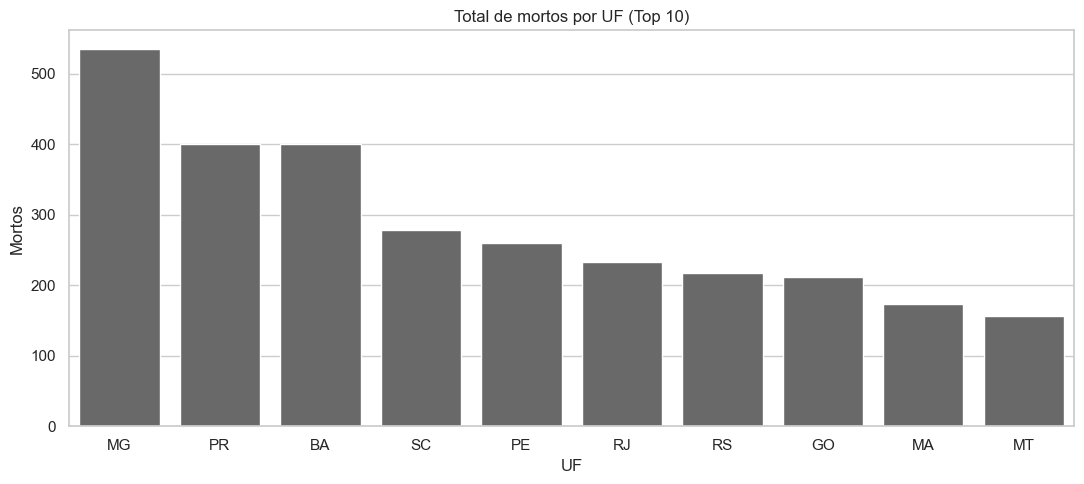

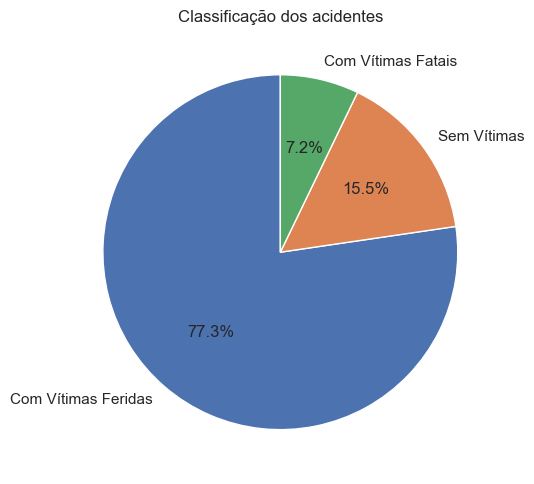

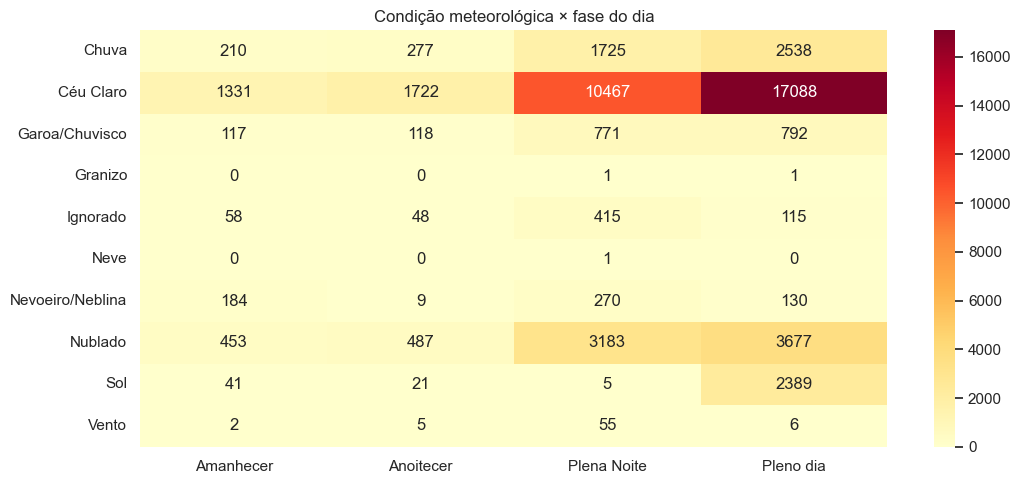

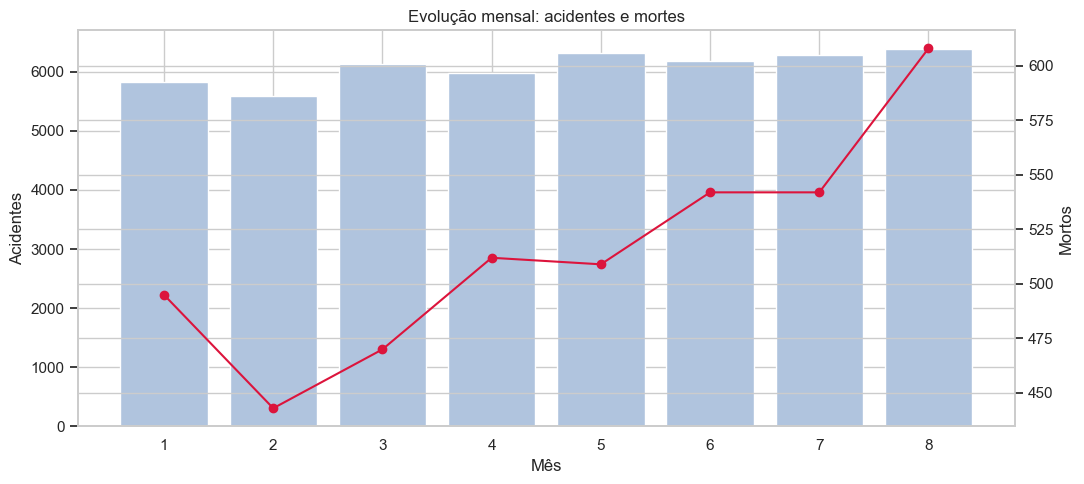

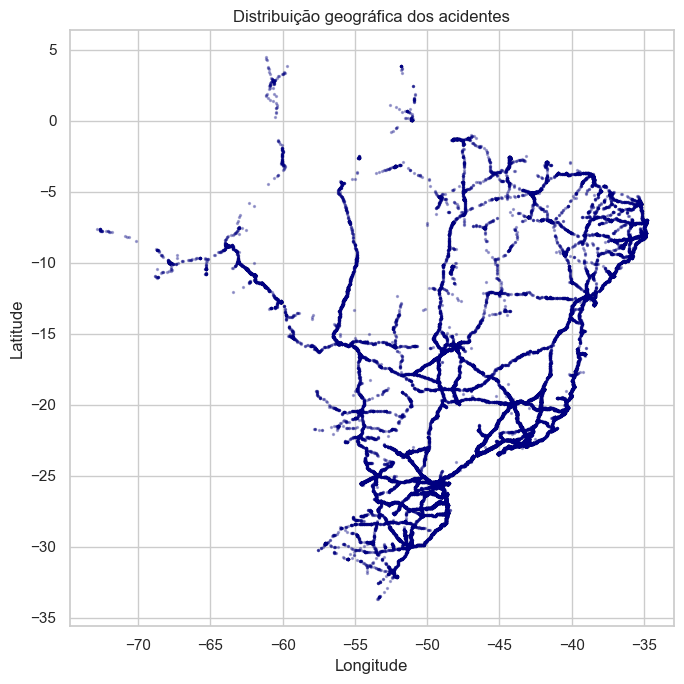

In [5]:
# -*- coding: utf-8 -*-
"""
Visualização de dados – Acidentes em rodovias federais (PRF / DATATRAN 2026)
Dica: cada bloco "# %%" funciona como uma célula no VS Code / Jupyter.
Instale as dependências com:  pip install pandas matplotlib seaborn
"""

# %% 1. Importações
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)

# %% 2. Leitura do CSV -> DataFrame
# O arquivo usa ';' como separador, encoding latin-1 e vírgula como decimal
CAMINHO = "Analise-Climatica-Brasil/datatran2026.csv"   # ajuste para o caminho do seu arquivo

# Resolve the CSV path correctly from the notebook location
base_dir = Path.cwd()
candidates = [
    Path(CAMINHO),                           # "Analise-Climatica-Brasil/datatran2026.csv"
    base_dir / CAMINHO,                      # ex.: .../new_fontes/Analise-Climatica-Brasil/datatran2026.csv
    base_dir.parent / CAMINHO,               # ex.: .../Analise-Climatica-Brasil/Analise-Climatica-Brasil/datatran2026.csv
    base_dir.parent / "datatran2026.csv",    # ex.: .../Analise-Climatica-Brasil/datatran2026.csv
    Path(r"c:\Users\49582707879\Documents\projeto_meteo\Analise-Climatica-Brasil\datatran2026.csv"),
]

for p in candidates:
    if p.exists():
        CAMINHO = str(p)
        break
else:
    raise FileNotFoundError(f"Arquivo não encontrado. Verifique o caminho atual: {CAMINHO}")

df = pd.read_csv(CAMINHO, sep=";", encoding="latin-1", decimal=",")

# %% 3. Visão geral
print("Formato:", df.shape)
print(df.dtypes)
display(df.head()) if "display" in globals() else print(df.head())
print("\nValores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])

# %% 4. Limpeza e tipagem
df["data_inversa"] = pd.to_datetime(df["data_inversa"], errors="coerce")
df["horario"] = pd.to_datetime(df["horario"], format="%H:%M:%S", errors="coerce")
df["hora"] = df["horario"].dt.hour
df["mes"] = df["data_inversa"].dt.month

# colunas numéricas que vieram com vírgula decimal
for col in ["km", "latitude", "longitude"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce")

# padroniza textos
df["municipio"] = df["municipio"].str.title()
df["dia_semana"] = df["dia_semana"].str.lower()

# %% 5. Acidentes por dia da semana
ordem_dias = ["segunda-feira", "terça-feira", "quarta-feira",
              "quinta-feira", "sexta-feira", "sábado", "domingo"]

ax = sns.countplot(data=df, x="dia_semana", order=ordem_dias, color="steelblue")
ax.set_title("Acidentes por dia da semana")
ax.set_xlabel("")
ax.set_ylabel("Nº de acidentes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# %% 6. Acidentes por hora do dia
por_hora = df.groupby("hora").size()
ax = por_hora.plot(kind="line", marker="o", color="darkorange")
ax.set_title("Acidentes por hora do dia")
ax.set_xlabel("Hora")
ax.set_ylabel("Nº de acidentes")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

# %% 7. Top 10 causas de acidente
top_causas = df["causa_acidente"].value_counts().head(10)
sns.barplot(x=top_causas.values, y=top_causas.index, color="indianred")
plt.title("Top 10 causas de acidente")
plt.xlabel("Nº de acidentes")
plt.ylabel("")
plt.tight_layout()
plt.show()

# %% 8. Top 10 UFs com mais acidentes
top_uf = df["uf"].value_counts().head(10)
sns.barplot(x=top_uf.index, y=top_uf.values, color="seagreen")
plt.title("Top 10 UFs com mais acidentes")
plt.xlabel("UF")
plt.ylabel("Nº de acidentes")
plt.tight_layout()
plt.show()

# %% 9. Mortos por UF (Top 10)
mortos_uf = df.groupby("uf")["mortos"].sum().sort_values(ascending=False).head(10)
sns.barplot(x=mortos_uf.index, y=mortos_uf.values, color="dimgray")
plt.title("Total de mortos por UF (Top 10)")
plt.xlabel("UF")
plt.ylabel("Mortos")
plt.tight_layout()
plt.show()

# %% 10. Classificação do acidente
classif = df["classificacao_acidente"].value_counts()
plt.pie(classif.values, labels=classif.index, autopct="%1.1f%%", startangle=90)
plt.title("Classificação dos acidentes")
plt.tight_layout()
plt.show()

# %% 11. Condição meteorológica x fase do dia
tab = pd.crosstab(df["condicao_metereologica"], df["fase_dia"])
sns.heatmap(tab, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Condição meteorológica × fase do dia")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

# %% 12. Evolução mensal de acidentes e mortes
mensal = df.groupby("mes").agg(acidentes=("id", "count"), mortos=("mortos", "sum"))
fig, ax1 = plt.subplots()
ax1.bar(mensal.index, mensal["acidentes"], color="lightsteelblue", label="Acidentes")
ax1.set_xlabel("Mês")
ax1.set_ylabel("Acidentes")
ax2 = ax1.twinx()
ax2.plot(mensal.index, mensal["mortos"], color="crimson", marker="o", label="Mortos")
ax2.set_ylabel("Mortos")
plt.title("Evolução mensal: acidentes e mortes")
fig.tight_layout()
plt.show()

# %% 13. Mapa de dispersão dos acidentes (lat/long)
geo = df.dropna(subset=["latitude", "longitude"])
geo = geo[(geo["latitude"].between(-34, 6)) & (geo["longitude"].between(-74, -34))]
plt.figure(figsize=(7, 7))
plt.scatter(geo["longitude"], geo["latitude"], s=2, alpha=0.3, color="navy")
plt.title("Distribuição geográfica dos acidentes")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

Formato: (48712, 30)
                 acidentes  mortos  feridos_graves  pct_acidentes  \
clima                                                               
Tempo bom            33064    2789            9320           67.9   
Nublado               7800     651            2083           16.0   
Chuva                 6550     534            1595           13.4   
Outros/Ignorado        637      47             189            1.3   
Neblina                593      94             190            1.2   
Vento                   68       6              20            0.1   

                 mortos_por_100  graves_por_100  
clima                                            
Tempo bom                  8.44           28.19  
Nublado                    8.35           26.71  
Chuva                      8.15           24.35  
Outros/Ignorado            7.38           29.67  
Neblina                   15.85           32.04  
Vento                      8.82           29.41  


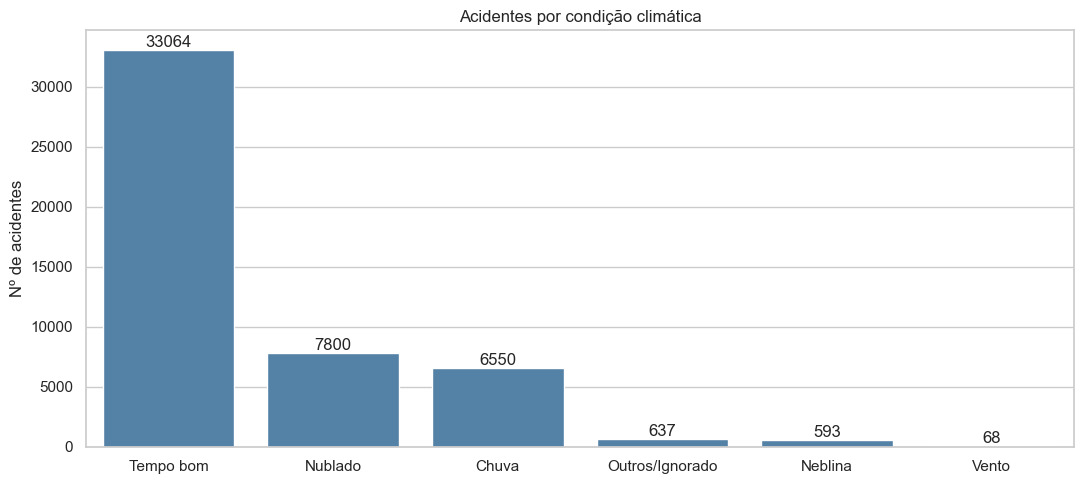

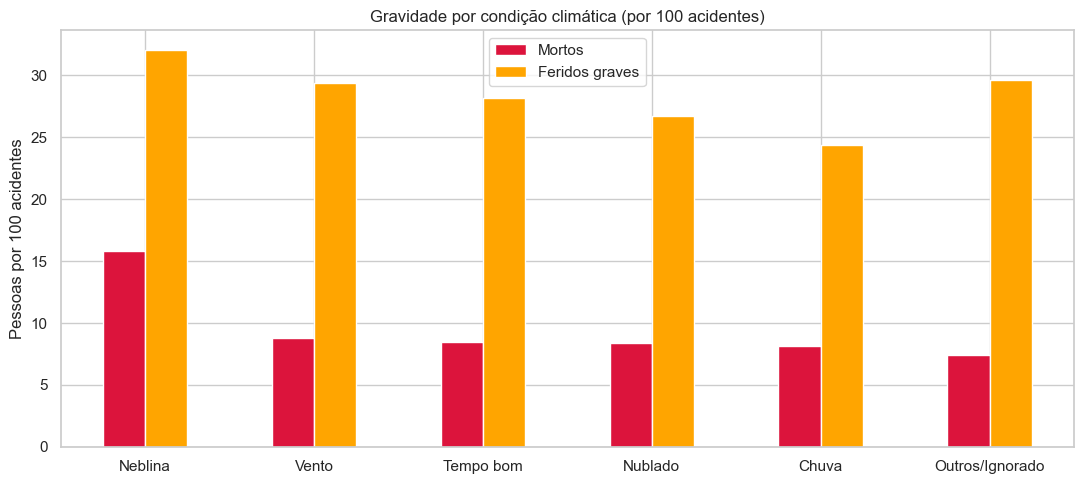

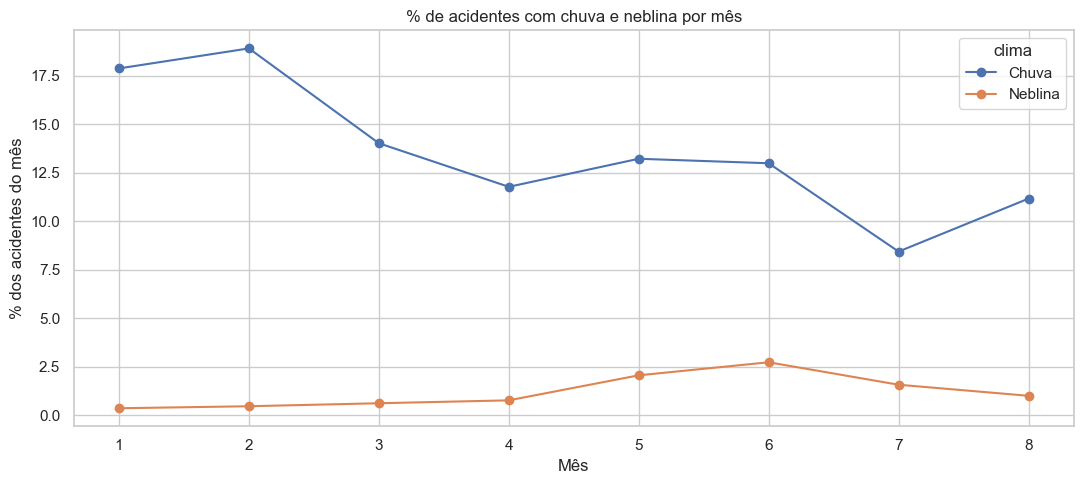

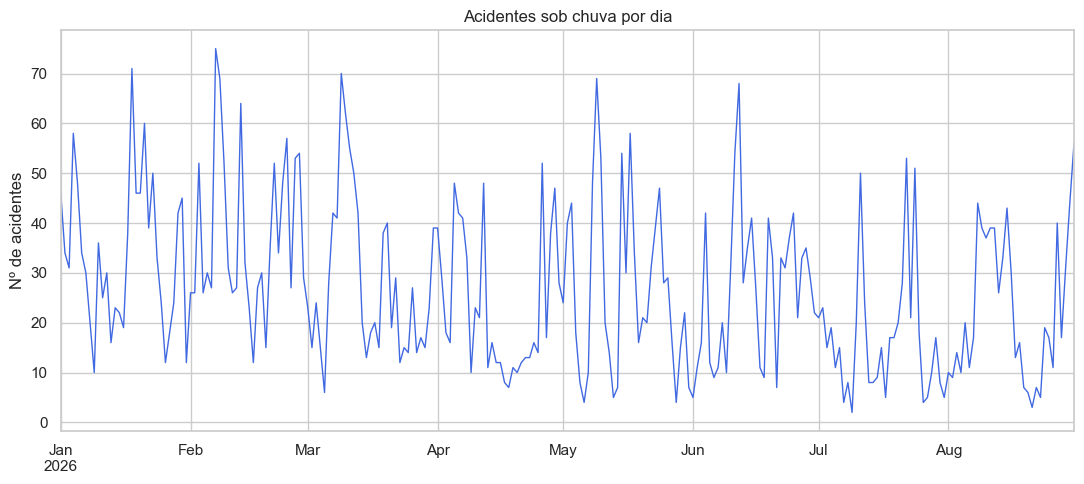

Top 5 dias com chuva:
 data_inversa
2026-02-07    75
2026-01-18    71
2026-03-09    70
2026-05-09    69
2026-02-08    69
dtype: int64


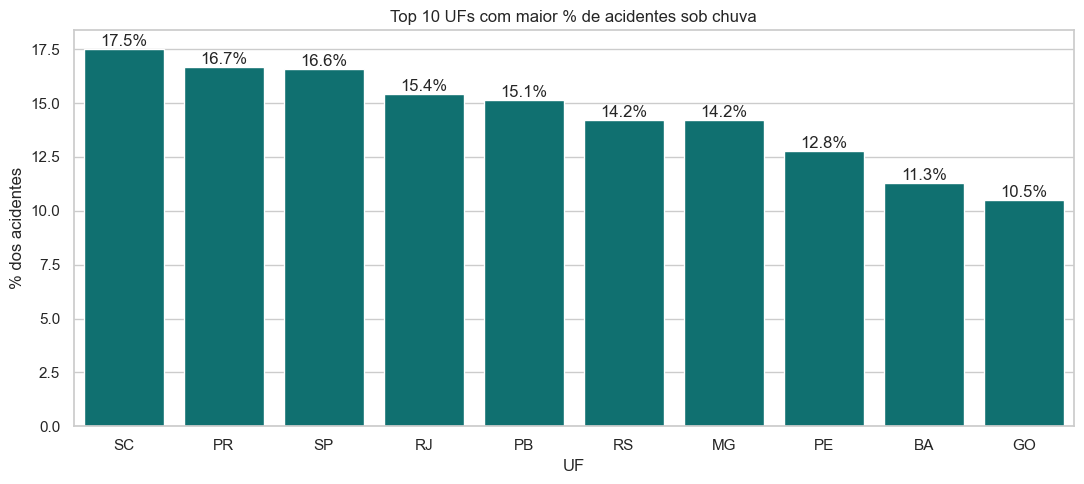

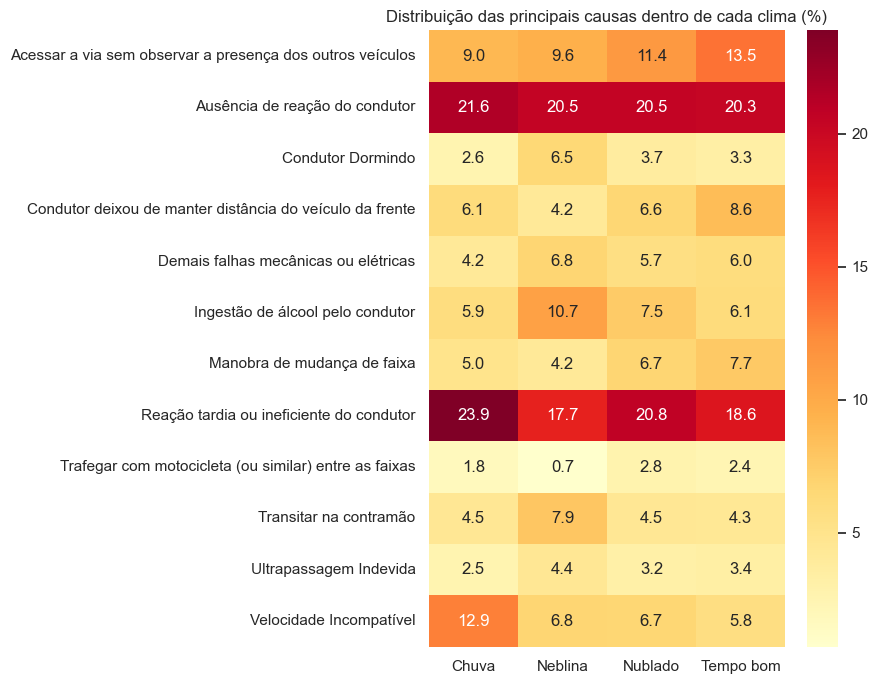

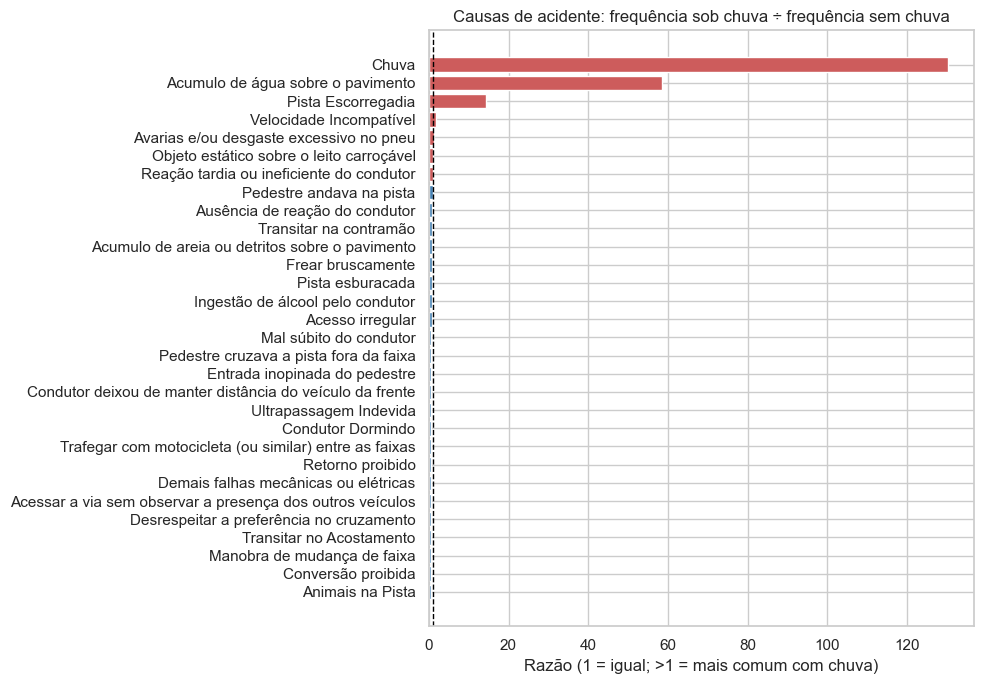

Acidentes sob chuva: 6550
Com causa climática registrada: 1355 (20.7%)

Causas mais apontadas quando havia chuva:
causa_acidente
Reação tardia ou ineficiente do condutor                     15.6
Ausência de reação do condutor                               14.1
Chuva                                                        10.5
Velocidade Incompatível                                       8.4
Acessar a via sem observar a presença dos outros veículos     5.9
Acumulo de água sobre o pavimento                             5.7
Pista Escorregadia                                            4.3
Condutor deixou de manter distância do veículo da frente      4.0
Ingestão de álcool pelo condutor                              3.9
Manobra de mudança de faixa                                   3.3
Name: proportion, dtype: float64


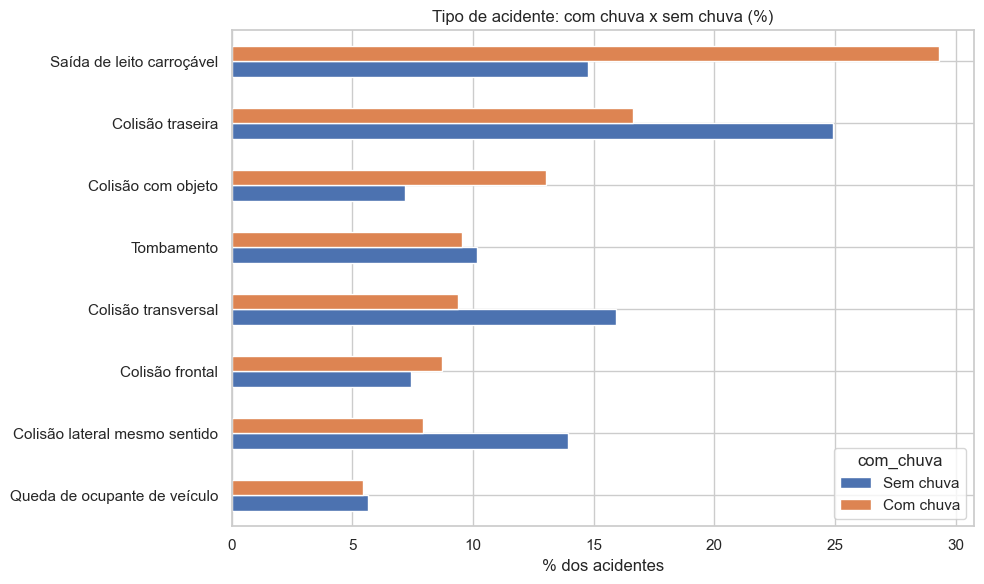

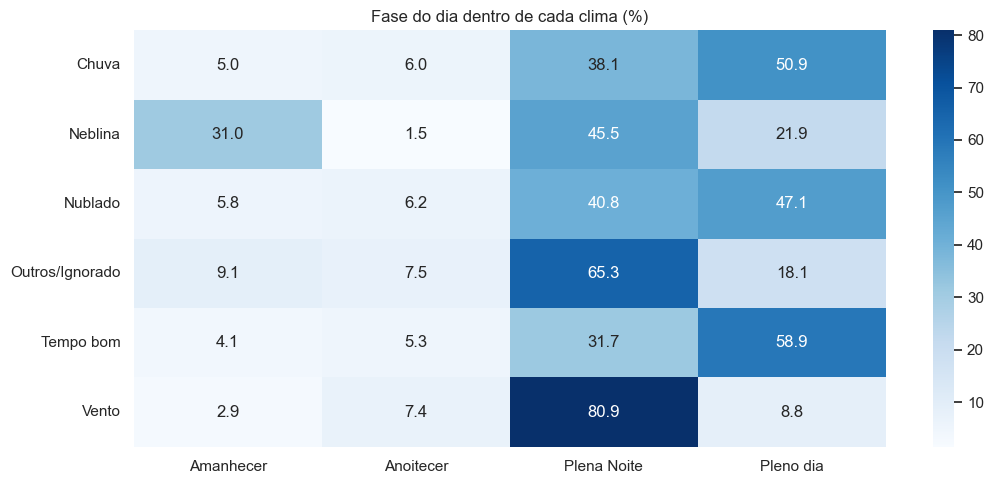

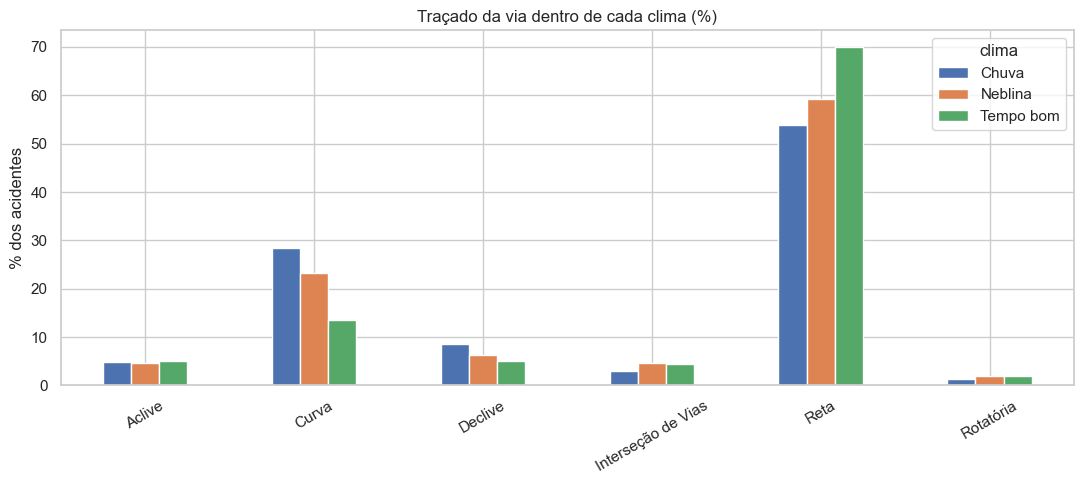

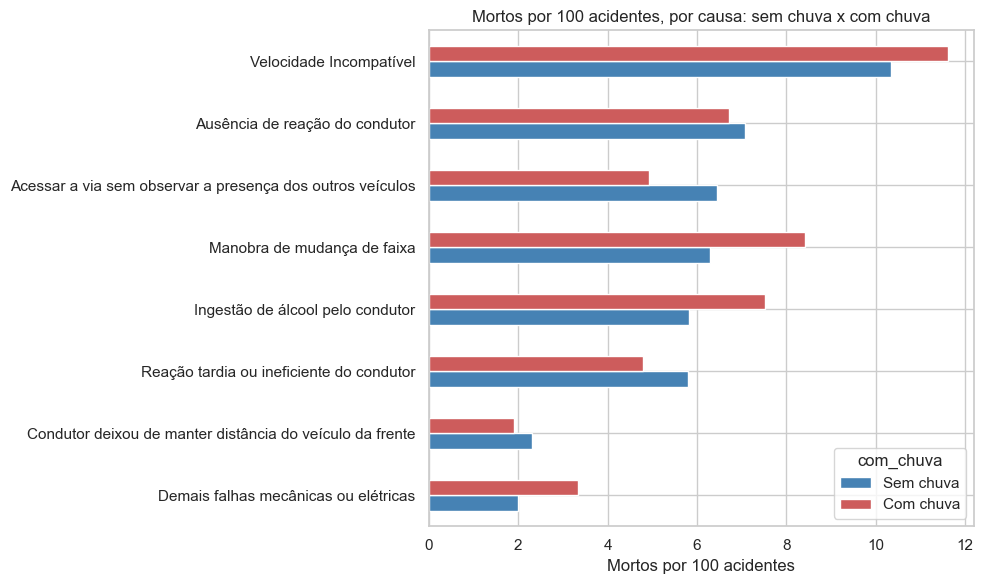

In [7]:
# -*- coding: utf-8 -*-
"""
Análise climática – Acidentes em rodovias federais (PRF / DATATRAN 2026)
Parte 1: foco em condições climáticas
Parte 2: relação do clima com as demais causas de acidente
Cada bloco "# %%" funciona como uma célula no VS Code / Jupyter.
Dependências: pip install pandas matplotlib seaborn
"""

# %% 1. Importações e configuração
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)

CAMINHO = "datatran2026.csv"   # ajuste para o caminho do seu arquivo


def mostrar():
    """Exibe o gráfico e fecha a figura, para o próximo gráfico começar do zero."""
    plt.show()
    plt.close("all")

# %% 2. Leitura -> DataFrame
# Resolve o arquivo DATATRAN mesmo que o notebook rode fora da pasta do CSV
search_paths = []
for p in candidates:
    p = Path(p)
    if not p.is_absolute():
        search_paths.append(base_dir / p)
    search_paths.append(p)

for path in search_paths:
    if path.exists():
        CAMINHO = str(path)
        break
else:
    matches = list(base_dir.rglob("datatran2026.csv"))
    if matches:
        CAMINHO = str(matches[0])
    else:
        raise FileNotFoundError(
            "Arquivo 'datatran2026.csv' não encontrado. Ajuste CAMINHO manualmente."
        )

df = pd.read_csv(CAMINHO, sep=";", encoding="latin-1")
print("Formato:", df.shape)

# %% 3. Limpeza e variáveis climáticas
df["data_inversa"] = pd.to_datetime(df["data_inversa"], errors="coerce")
df["mes"] = df["data_inversa"].dt.month
df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S", errors="coerce").dt.hour

for col in ["km", "latitude", "longitude"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce")

# Agrupa as condições meteorológicas em categorias mais simples
mapa_clima = {
    "Chuva": "Chuva",
    "Garoa/Chuvisco": "Chuva",
    "Granizo": "Chuva",
    "Nevoeiro/Neblina": "Neblina",
    "Vento": "Vento",
    "Céu Claro": "Tempo bom",
    "Sol": "Tempo bom",
    "Nublado": "Nublado",
}
df["clima"] = df["condicao_metereologica"].map(mapa_clima).fillna("Outros/Ignorado")

# Flags úteis
df["com_chuva"] = df["clima"].eq("Chuva")
df["clima_adverso"] = df["clima"].isin(["Chuva", "Neblina", "Vento"])

# Causas que o próprio registro atribui a fenômenos climáticos
causas_climaticas = ["Chuva", "Neblina", "Fumaça", "Demais Fenômenos da natureza",
                     "Acumulo de água sobre o pavimento", "Pista Escorregadia"]
df["causa_climatica"] = df["causa_acidente"].isin(causas_climaticas)

# =====================================================================
# PARTE 1 – FOCO NO CLIMA
# =====================================================================

# %% 4. Resumo por condição meteorológica
resumo = (
    df.groupby("clima")
    .agg(acidentes=("id", "count"),
         mortos=("mortos", "sum"),
         feridos_graves=("feridos_graves", "sum"))
    .assign(pct_acidentes=lambda t: (t["acidentes"] / t["acidentes"].sum() * 100).round(1),
            mortos_por_100=lambda t: (t["mortos"] / t["acidentes"] * 100).round(2),
            graves_por_100=lambda t: (t["feridos_graves"] / t["acidentes"] * 100).round(2))
    .sort_values("acidentes", ascending=False)
)
print(resumo)

# %% 5. Volume de acidentes por clima
ax = sns.barplot(x=resumo.index, y=resumo["acidentes"], color="steelblue")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("Acidentes por condição climática")
ax.set_xlabel("")
ax.set_ylabel("Nº de acidentes")
plt.tight_layout()
mostrar()

# %% 6. Gravidade por clima (mortos e feridos graves por 100 acidentes)
grav = resumo[["mortos_por_100", "graves_por_100"]].sort_values("mortos_por_100", ascending=False)
grav.plot(kind="bar", color=["crimson", "orange"])
plt.title("Gravidade por condição climática (por 100 acidentes)")
plt.xlabel("")
plt.ylabel("Pessoas por 100 acidentes")
plt.xticks(rotation=0)
plt.legend(["Mortos", "Feridos graves"])
plt.tight_layout()
mostrar()

# %% 7. Sazonalidade: % de acidentes com chuva e neblina por mês
sazonal = (
    df.groupby("mes")["clima"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack()[["Chuva", "Neblina"]]
)
sazonal.plot(marker="o")
plt.title("% de acidentes com chuva e neblina por mês")
plt.xlabel("Mês")
plt.ylabel("% dos acidentes do mês")
plt.xticks(sazonal.index)
plt.tight_layout()
mostrar()

# %% 8. Dias com mais acidentes sob chuva
por_dia = df[df["com_chuva"]].groupby("data_inversa").size()
ax = por_dia.plot(color="royalblue", linewidth=1)
ax.set_title("Acidentes sob chuva por dia")
ax.set_xlabel("")
ax.set_ylabel("Nº de acidentes")
plt.tight_layout()
mostrar()
print("Top 5 dias com chuva:\n", por_dia.sort_values(ascending=False).head(5))

# %% 9. UFs onde a chuva pesa mais (% dos acidentes da UF) – UFs com 500+ acidentes
uf = df.groupby("uf").agg(total=("id", "count"), chuva=("com_chuva", "sum"))
uf = uf[uf["total"] >= 500]
uf["pct_chuva"] = uf["chuva"] / uf["total"] * 100
uf = uf.sort_values("pct_chuva", ascending=False).head(10)
ax = sns.barplot(x=uf.index, y=uf["pct_chuva"], color="teal")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_title("Top 10 UFs com maior % de acidentes sob chuva")
ax.set_xlabel("UF")
ax.set_ylabel("% dos acidentes")
plt.tight_layout()
mostrar()

# =====================================================================
# PARTE 2 – RELAÇÃO DO CLIMA COM AS DEMAIS CAUSAS
# =====================================================================

# %% 10. Causas mais frequentes em cada clima (heatmap, % dentro de cada clima)
top_causas = df["causa_acidente"].value_counts().head(12).index
base = df[df["causa_acidente"].isin(top_causas) & df["clima"].isin(["Tempo bom", "Nublado", "Chuva", "Neblina"])]
tab = pd.crosstab(base["causa_acidente"], base["clima"], normalize="columns") * 100
plt.figure(figsize=(9, 7))
sns.heatmap(tab, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Distribuição das principais causas dentro de cada clima (%)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
mostrar()

# %% 11. Quais causas aumentam com a chuva? (razão chuva / sem chuva)
# razão > 1 => a causa é proporcionalmente mais comum em acidentes sob chuva
dist_chuva = df[df["com_chuva"]]["causa_acidente"].value_counts(normalize=True)
dist_seco = df[~df["com_chuva"]]["causa_acidente"].value_counts(normalize=True)
razao = (dist_chuva / dist_seco).dropna()
# só causas com volume mínimo, para evitar razões instáveis
volume = df["causa_acidente"].value_counts()
razao = razao[volume[razao.index] >= 200].sort_values(ascending=False)

plt.figure(figsize=(10, 7))
cores = ["indianred" if v > 1 else "steelblue" for v in razao.values]
plt.barh(razao.index[::-1], razao.values[::-1], color=cores[::-1])
plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.title("Causas de acidente: frequência sob chuva ÷ frequência sem chuva")
plt.xlabel("Razão (1 = igual; >1 = mais comum com chuva)")
plt.tight_layout()
mostrar()

# %% 12. A chuva é registrada como causa? (presente x apontada)
chuva_df = df[df["com_chuva"]]
print("Acidentes sob chuva:", len(chuva_df))
print("Com causa climática registrada:", chuva_df["causa_climatica"].sum(),
      f"({chuva_df['causa_climatica'].mean() * 100:.1f}%)")
print("\nCausas mais apontadas quando havia chuva:")
print(chuva_df["causa_acidente"].value_counts(normalize=True).mul(100).round(1).head(10))

# %% 13. Tipo de acidente: chuva x sem chuva
tipos_top = df["tipo_acidente"].value_counts().head(8).index
tipo = (
    df[df["tipo_acidente"].isin(tipos_top)]
    .groupby("com_chuva")["tipo_acidente"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack(0)
    .rename(columns={False: "Sem chuva", True: "Com chuva"})
    .sort_values("Com chuva")
)
tipo.plot(kind="barh", figsize=(10, 6))
plt.title("Tipo de acidente: com chuva x sem chuva (%)")
plt.xlabel("% dos acidentes")
plt.ylabel("")
plt.tight_layout()
mostrar()

# %% 14. Clima x fase do dia (neblina costuma se concentrar no amanhecer)
fase = pd.crosstab(df["clima"], df["fase_dia"], normalize="index") * 100
sns.heatmap(fase, annot=True, fmt=".1f", cmap="Blues")
plt.title("Fase do dia dentro de cada clima (%)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
mostrar()

# %% 15. Clima x traçado da via (curva, reta...) – usa o 1º traçado informado
df["tracado_principal"] = df["tracado_via"].astype(str).str.split(";").str[0]
tracados = df["tracado_principal"].value_counts().head(6).index
trac = (
    df[df["tracado_principal"].isin(tracados) & df["clima"].isin(["Tempo bom", "Chuva", "Neblina"])]
    .pipe(lambda d: pd.crosstab(d["tracado_principal"], d["clima"], normalize="columns") * 100)
)
trac.plot(kind="bar")
plt.title("Traçado da via dentro de cada clima (%)")
plt.xlabel("")
plt.ylabel("% dos acidentes")
plt.xticks(rotation=30)
plt.tight_layout()
mostrar()

# %% 16. Gravidade das causas sob chuva x sem chuva
# mortos por 100 acidentes, nas 8 causas mais comuns
causas8 = df["causa_acidente"].value_counts().head(8).index
g = (
    df[df["causa_acidente"].isin(causas8)]
    .groupby(["causa_acidente", "com_chuva"])
    .agg(acid=("id", "count"), mortos=("mortos", "sum"))
)
g["mortos_por_100"] = g["mortos"] / g["acid"] * 100
g = g["mortos_por_100"].unstack().rename(columns={False: "Sem chuva", True: "Com chuva"})
g.sort_values("Sem chuva").plot(kind="barh", figsize=(10, 6), color=["steelblue", "indianred"])
plt.title("Mortos por 100 acidentes, por causa: sem chuva x com chuva")
plt.xlabel("Mortos por 100 acidentes")
plt.ylabel("")
plt.tight_layout()
mostrar()

Formato: (358865, 19)
Região                     object
UF                         object
Cidade                     object
Sexo                       object
Faixa Etária               object
Data Finalização           object
Tempo Resposta            float64
Nome Fantasia              object
Segmento de Mercado        object
Área                       object
Assunto                    object
Grupo Problema             object
Problema                   object
Como Comprou Contratou     object
Procurou Empresa           object
Respondida                 object
Situação                   object
Avaliação Reclamação       object
Nota do Consumidor        float64
dtype: object

Reclamações de marketplaces/logística: 27,174 de 358,865
empresa
Mercado Livre    9488
Shopee           4568
Amazon           4246
Casas Bahia      3070
Magalu           1647
Correios         1275
Enjoei            534
Netshoes          482
KaBuM!            354
Carrefour.com     319
Centauro          316
Jadlog    

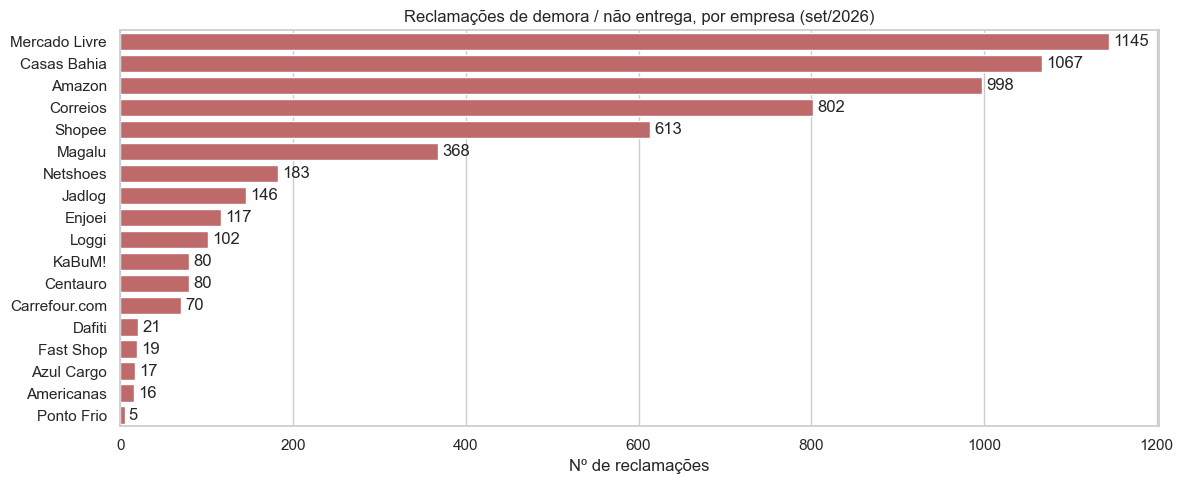

               total  demora  pct_demora
empresa                                 
Loggi            149     102        68.5
Correios        1275     802        62.9
Jadlog           270     146        54.1
Netshoes         482     183        38.0
Casas Bahia     3070    1067        34.8
Centauro         316      80        25.3
Amazon          4246     998        23.5
KaBuM!           354      80        22.6
Magalu          1647     368        22.3
Carrefour.com    319      70        21.9
Enjoei           534     117        21.9
Fast Shop         88      19        21.6
Dafiti           110      21        19.1
Shopee          4568     613        13.4
Mercado Livre   9488    1145        12.1
Americanas       183      16         8.7


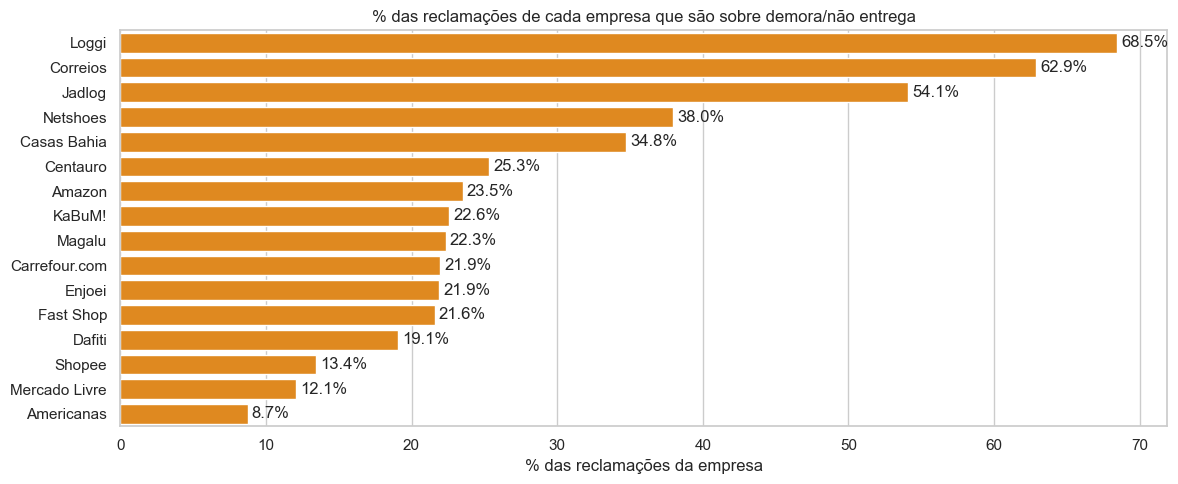

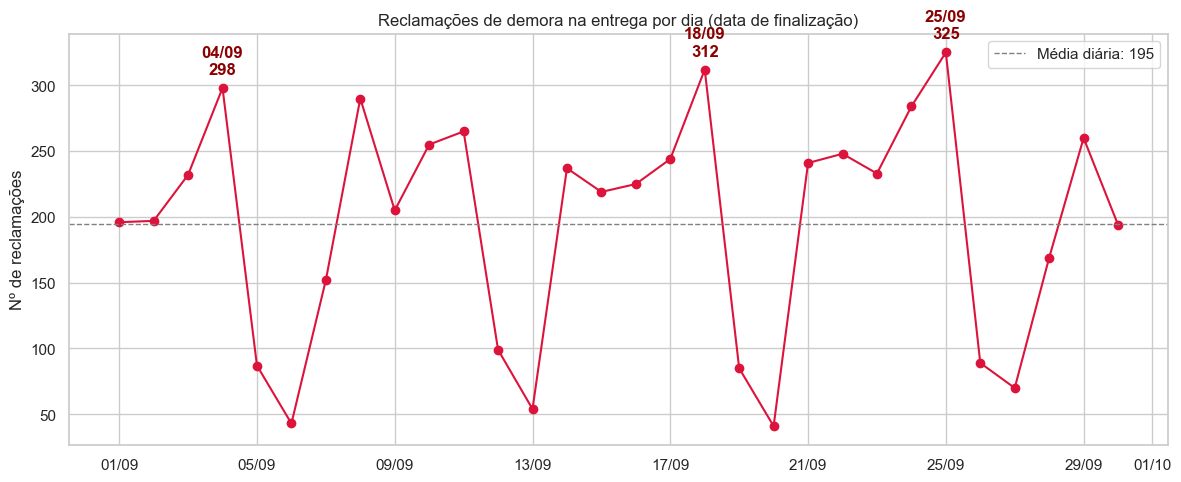


Datas de pico:
  25/09/2026 (Friday): 325 reclamações
  18/09/2026 (Friday): 312 reclamações
  04/09/2026 (Friday): 298 reclamações

Dia de pico de cada empresa (reclamações de demora):
  Mercado Livre      pico em 25/09/2026: 72 (média diária: 38.2)
  Casas Bahia        pico em 04/09/2026: 77 (média diária: 35.6)
  Amazon             pico em 18/09/2026: 70 (média diária: 33.3)
  Correios           pico em 25/09/2026: 49 (média diária: 26.7)
  Shopee             pico em 24/09/2026: 42 (média diária: 20.4)
  Magalu             pico em 25/09/2026: 31 (média diária: 12.3)
  Netshoes           pico em 08/09/2026: 13 (média diária: 7.0)
  Jadlog             pico em 18/09/2026: 13 (média diária: 5.0)


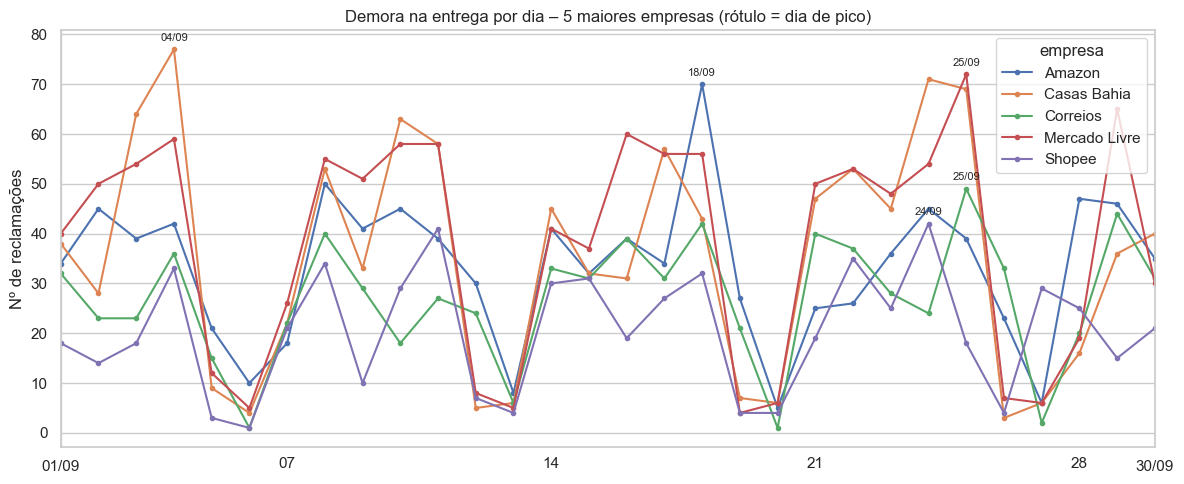

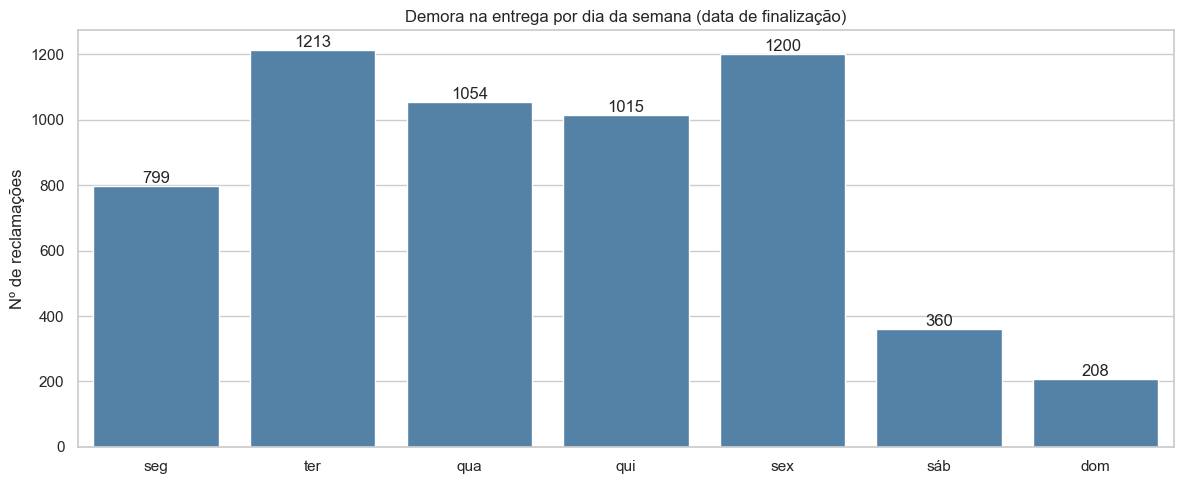

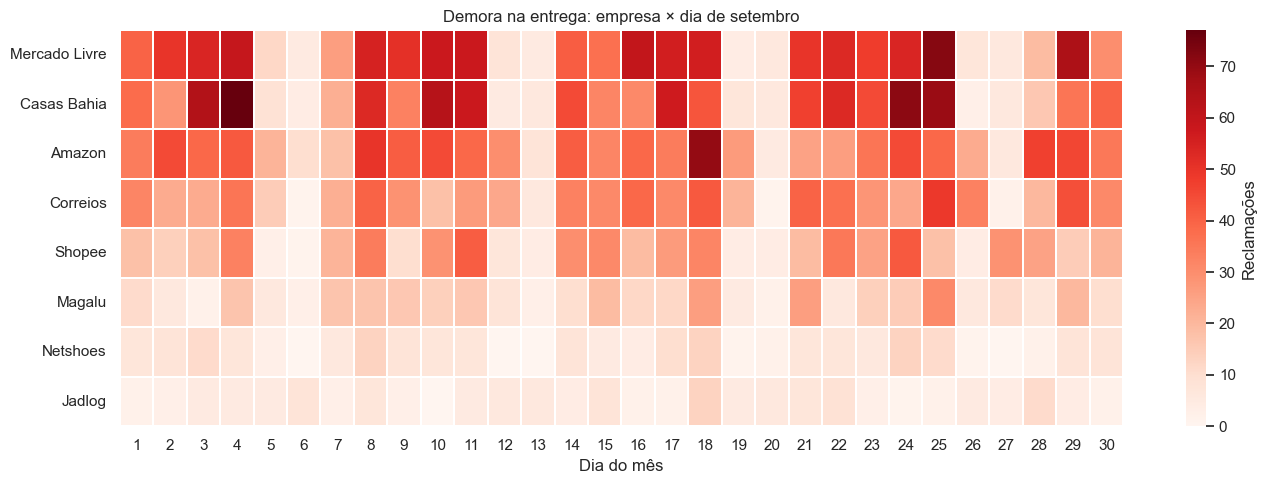


Resposta e satisfação (demora na entrega):
               reclamacoes  respondida_pct  tempo_resposta_dias  \
empresa                                                           
Mercado Livre         1145          100.00                 7.99   
Casas Bahia           1067          100.00                 8.28   
Amazon                 998           95.59                 6.59   
Correios               802          100.00                 2.81   
Shopee                 613           93.15                 9.00   
Magalu                 368           70.11                 7.20   
Netshoes               183           99.45                 8.21   
Jadlog                 146            0.00                  NaN   
Enjoei                 117           28.21                 9.52   
Loggi                  102           99.02                 6.81   
Centauro                80            0.00                  NaN   
KaBuM!                  80           31.25                 9.36   
Carrefour.com     

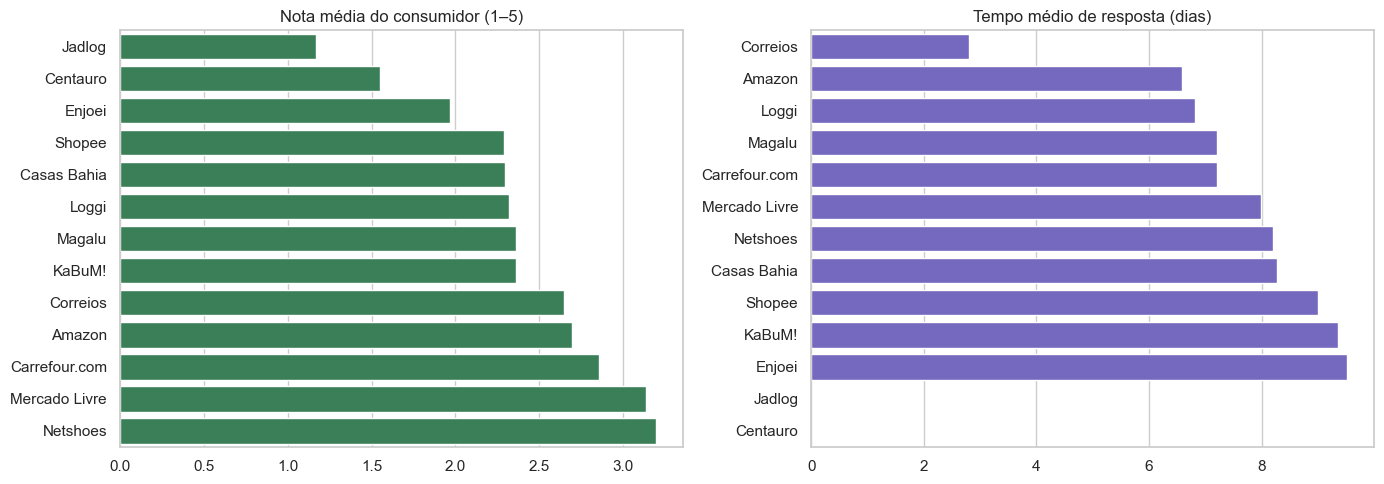

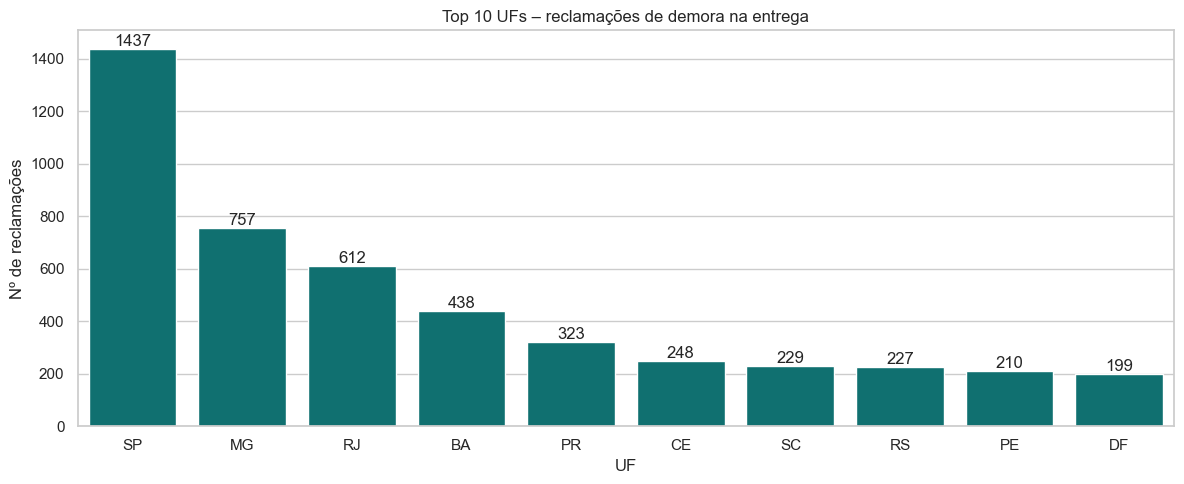

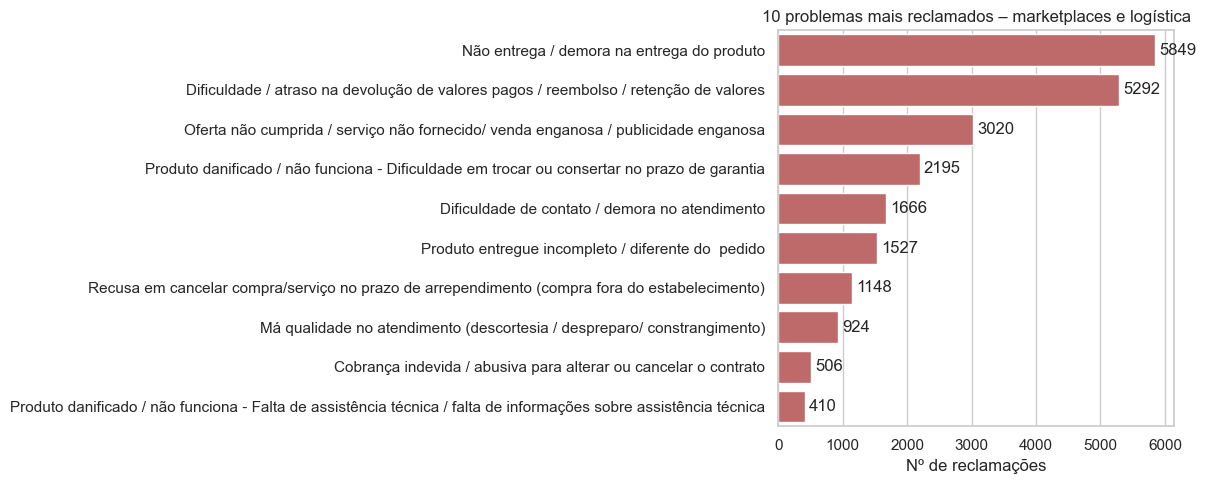

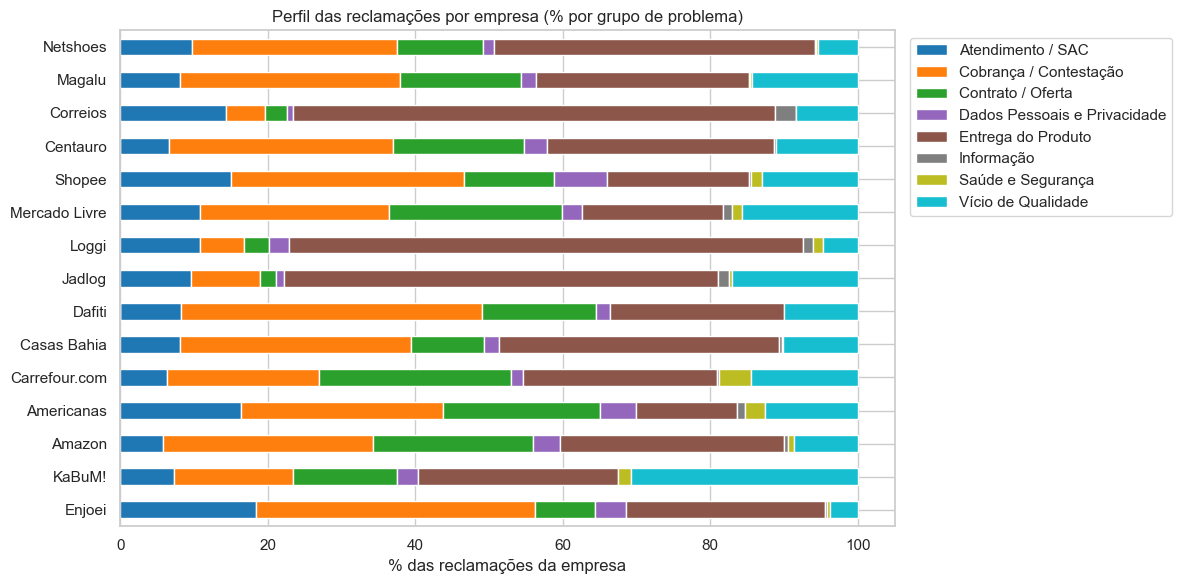


                             total  demora  entrega_geral  pct_demora  \
tipo                                                                   
Logística / Transportadora   1731    1067           1120        61.6   
Marketplace / E-commerce    25443    4782           6345        18.8   

                            pct_grupo_entrega  
tipo                                           
Logística / Transportadora               64.7  
Marketplace / E-commerce                 24.9  

Demora x outros problemas (mesmas empresas):
                    reclamacoes  respondida_pct  tempo_resposta  nota
categoria_problema                                                   
Demora/não entrega         5849           90.36            7.03  2.61
Outros problemas          21325           91.69            7.89  2.71


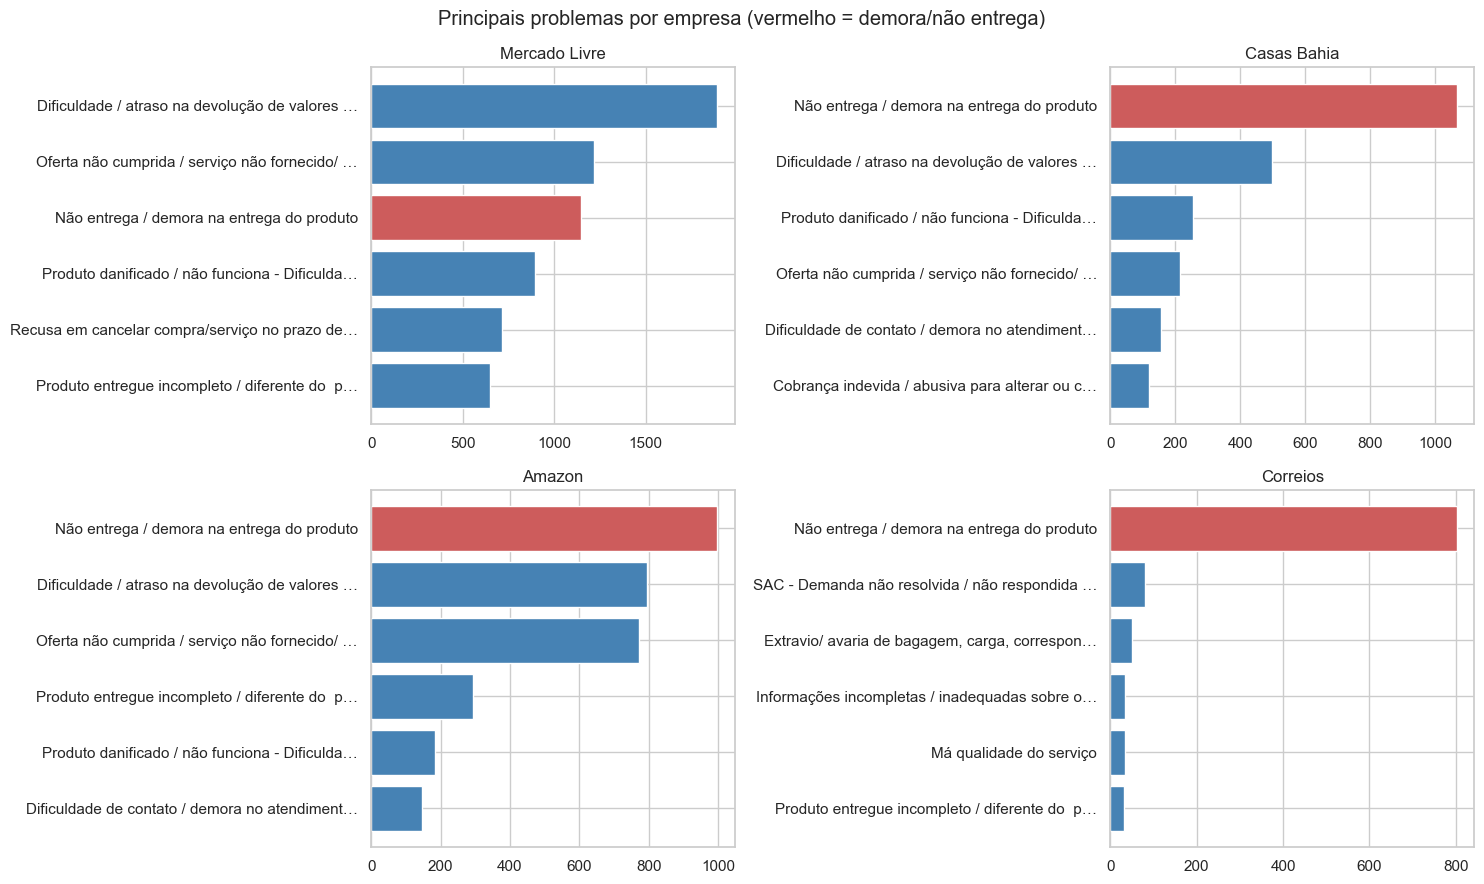

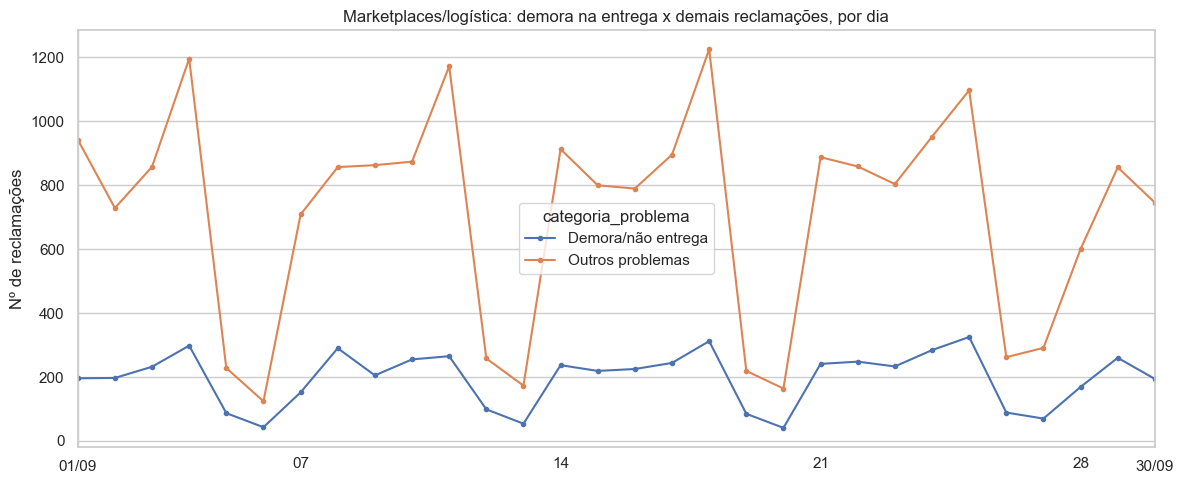


Correlação diária entre demora e demais reclamações: 0.96


In [12]:
# -*- coding: utf-8 -*-
"""
Reclamações finalizadas (Consumidor.gov.br) – Setembro/2026
Parte 1: marketplaces e empresas de logística + reclamações de demora na entrega
Parte 2: relação da demora na entrega com os demais problemas

ATENÇÃO: a coluna de data do arquivo é "Data Finalização" (dia em que a reclamação
foi encerrada), e não o dia em que o consumidor abriu a reclamação.

Cada bloco "# %%" funciona como uma célula no VS Code / Jupyter.
Dependências: pip install pandas matplotlib seaborn
"""

# %% 1. Importações e configuração
import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)

CAMINHO = "finalizadas_2026-09.csv"   # ajuste para o caminho do seu arquivo


def mostrar():
    """Exibe o gráfico e fecha a figura, para o próximo gráfico começar do zero."""
    plt.show()
    plt.close("all")


# %% 2. Leitura -> DataFrame (separador ';' e BOM no início do arquivo)
# Busca o arquivo em pastas comuns do projeto / notebook
base_dir = Path.cwd().resolve()

# tenta vários locais plausíveis
candidates = [
    Path(CAMINHO),
    base_dir / CAMINHO,
    base_dir.parent / CAMINHO,
    base_dir / "new_fontes" / CAMINHO,
    base_dir / "Analise-Climatica-Brasil" / "new_fontes" / CAMINHO,
    base_dir / ".." / "new_fontes" / CAMINHO,
]

for p in candidates:
    p = p.resolve()
    if p.exists():
        CAMINHO = str(p)
        break
else:
    matches = list(base_dir.rglob("finalizadas_2026-09.csv"))
    if matches:
        CAMINHO = str(matches[0])
    else:
        raise FileNotFoundError(
            "Arquivo 'finalizadas_2026-09.csv' não encontrado.\n"
            f"Diretório atual: {base_dir}\n"
            "Verifique se o arquivo está na pasta do projeto ou ajuste CAMINHO manualmente."
        )

df = pd.read_csv(CAMINHO, sep=";", encoding="utf-8-sig", low_memory=False)
df.columns = df.columns.str.strip()
print("Formato:", df.shape)
print(df.dtypes)

# %% 3. Limpeza
df["data"] = pd.to_datetime(df["Data Finalização"], errors="coerce")
df["dia_semana"] = df["data"].dt.dayofweek          # 0 = segunda
df["Região"] = df["Região"].str.strip()

# %% 4. Seleção de marketplaces e empresas de logística
# (regex no Nome Fantasia, nome padronizado, tipo). Há variações de nome no arquivo
# (ex.: "Casas Bahia" e "Casasbahia.com"), por isso a padronização.
EMPRESAS = [
    # --- marketplaces / e-commerce ---
    (r"mercado livre",                    "Mercado Livre",   "Marketplace / E-commerce"),
    (r"shopee brasil",                    "Shopee",          "Marketplace / E-commerce"),
    (r"amazon\.com",                      "Amazon",          "Marketplace / E-commerce"),
    (r"magazine luiza - loja online",     "Magalu",          "Marketplace / E-commerce"),
    (r"casas ?bahia(\.com)?$",            "Casas Bahia",     "Marketplace / E-commerce"),
    (r"americanas",                       "Americanas",      "Marketplace / E-commerce"),
    (r"netshoes",                         "Netshoes",        "Marketplace / E-commerce"),
    (r"kabum",                            "KaBuM!",          "Marketplace / E-commerce"),
    (r"carrefour\.com",                   "Carrefour.com",   "Marketplace / E-commerce"),
    (r"^centauro(\.com\.br)?$",           "Centauro",        "Marketplace / E-commerce"),
    (r"dafiti",                           "Dafiti",          "Marketplace / E-commerce"),
    (r"fast shop",                        "Fast Shop",       "Marketplace / E-commerce"),
    (r"ponto frio",                       "Ponto Frio",      "Marketplace / E-commerce"),
    (r"enjoei",                           "Enjoei",          "Marketplace / E-commerce"),
    (r"aliexpress|shein|temu",            "AliExpress/Shein/Temu", "Marketplace / E-commerce"),
    # --- logística / transportadoras ---
    (r"correios",                         "Correios",        "Logística / Transportadora"),
    (r"jadlog",                           "Jadlog",          "Logística / Transportadora"),
    (r"loggi",                            "Loggi",           "Logística / Transportadora"),
    (r"azul log",                         "Azul Cargo",      "Logística / Transportadora"),
    (r"kangu|total express|sequoia|j&t|jt express|mandaê", "Outras transportadoras", "Logística / Transportadora"),
]


def classifica(nome):
    nome = str(nome).strip().lower()
    for padrao, padrao_nome, tipo in EMPRESAS:
        if re.search(padrao, nome):
            return pd.Series([padrao_nome, tipo])
    return pd.Series([None, None])


# classifica só os nomes únicos (rápido) e depois junta ao DataFrame
nomes = pd.Series(df["Nome Fantasia"].dropna().unique())
mapa = nomes.to_frame("Nome Fantasia")
mapa[["empresa", "tipo"]] = mapa["Nome Fantasia"].apply(classifica)
df = df.merge(mapa, on="Nome Fantasia", how="left")

alvo = df.dropna(subset=["empresa"]).copy()
print(f"\nReclamações de marketplaces/logística: {len(alvo):,} de {len(df):,}")
print(alvo["empresa"].value_counts())

# %% 5. Definição de "demora na entrega"
# No arquivo, o problema se chama "Não entrega / demora na entrega do produto"
alvo["demora_entrega"] = alvo["Problema"].str.contains(
    "demora na entrega do produto", case=False, na=False
)
alvo["grupo_entrega"] = alvo["Grupo Problema"].eq("Entrega do Produto")  # inclui entrega errada/incompleta

print("\nReclamações de demora/não entrega:", alvo["demora_entrega"].sum())
print("Grupo 'Entrega do Produto' (inclui entregas erradas):", alvo["grupo_entrega"].sum())

entrega = alvo[alvo["demora_entrega"]].copy()

# =====================================================================
# PARTE 1 – FOCO EM DEMORA NA ENTREGA
# =====================================================================

# %% 6. Ranking: empresas com mais reclamações de demora na entrega
rank = entrega["empresa"].value_counts()
ax = sns.barplot(x=rank.values, y=rank.index, color="indianred")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_title("Reclamações de demora / não entrega, por empresa (set/2026)")
ax.set_xlabel("Nº de reclamações")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 7. Peso da demora dentro de cada empresa (% das reclamações da empresa)
tot = alvo.groupby("empresa").agg(total=("Problema", "size"), demora=("demora_entrega", "sum"))
tot["pct_demora"] = tot["demora"] / tot["total"] * 100
tot = tot[tot["total"] >= 50].sort_values("pct_demora", ascending=False)
print(tot.round(1))

ax = sns.barplot(x=tot["pct_demora"], y=tot.index, color="darkorange")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("% das reclamações de cada empresa que são sobre demora/não entrega")
ax.set_xlabel("% das reclamações da empresa")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 8. Evolução diária (total) com as datas de pico destacadas
diario = entrega.groupby("data").size()
media = diario.mean()
picos = diario.nlargest(3)

fig, ax = plt.subplots()
ax.plot(diario.index, diario.values, marker="o", color="crimson")
ax.axhline(media, color="gray", linestyle="--", linewidth=1, label=f"Média diária: {media:.0f}")
for dt, v in picos.items():
    ax.annotate(f"{dt:%d/%m}\n{v}", (dt, v), textcoords="offset points",
                xytext=(0, 10), ha="center", fontweight="bold", color="darkred")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Reclamações de demora na entrega por dia (data de finalização)")
ax.set_ylabel("Nº de reclamações")
ax.legend()
plt.tight_layout()
mostrar()

print("\nDatas de pico:")
for dt, v in picos.items():
    print(f"  {dt:%d/%m/%Y} ({dt:%A}): {v} reclamações")

# %% 9. Datas de pico por empresa
print("\nDia de pico de cada empresa (reclamações de demora):")
por_emp_dia = entrega.groupby(["empresa", "data"]).size()
for emp in rank.index[:8]:
    s = por_emp_dia[emp]
    print(f"  {emp:<18} pico em {s.idxmax():%d/%m/%Y}: {s.max()} (média diária: {s.mean():.1f})")

# %% 10. Evolução diária das 5 maiores empresas
top5 = rank.head(5).index
pivot = (entrega[entrega["empresa"].isin(top5)]
         .groupby(["data", "empresa"]).size().unstack(fill_value=0))
ax = pivot.plot(marker="o", markersize=3)
for emp in pivot.columns:
    dt = pivot[emp].idxmax()
    ax.annotate(f"{dt:%d/%m}", (dt, pivot[emp].max()), textcoords="offset points",
                xytext=(0, 6), ha="center", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Demora na entrega por dia – 5 maiores empresas (rótulo = dia de pico)")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# %% 11. Padrão por dia da semana
nomes_dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
sem = entrega["dia_semana"].value_counts().sort_index()
ax = sns.barplot(x=[nomes_dias[i] for i in sem.index], y=sem.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("Demora na entrega por dia da semana (data de finalização)")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# %% 12. Mapa de calor: empresa x dia do mês
heat = (entrega[entrega["empresa"].isin(rank.head(8).index)]
        .assign(dia=lambda d: d["data"].dt.day)
        .groupby(["empresa", "dia"]).size().unstack(fill_value=0)
        .reindex(rank.head(8).index))
plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="Reds", linewidths=0.3, cbar_kws={"label": "Reclamações"})
plt.title("Demora na entrega: empresa × dia de setembro")
plt.xlabel("Dia do mês")
plt.ylabel("")
plt.tight_layout()
mostrar()

# %% 13. Resposta, prazo e satisfação (por empresa)
qual = (entrega.groupby("empresa")
        .agg(reclamacoes=("Problema", "size"),
             respondida_pct=("Respondida", lambda s: (s == "S").mean() * 100),
             tempo_resposta_dias=("Tempo Resposta", "mean"),
             nota_consumidor=("Nota do Consumidor", "mean"),
             avaliadas=("Nota do Consumidor", "count"))
        .sort_values("reclamacoes", ascending=False)
        .round(2))
print("\nResposta e satisfação (demora na entrega):")
print(qual)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
q = qual[qual["reclamacoes"] >= 30].sort_values("nota_consumidor")
sns.barplot(x=q["nota_consumidor"], y=q.index, color="seagreen", ax=axes[0])
axes[0].set_title("Nota média do consumidor (1–5)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
q2 = qual[qual["reclamacoes"] >= 30].sort_values("tempo_resposta_dias")
sns.barplot(x=q2["tempo_resposta_dias"], y=q2.index, color="slateblue", ax=axes[1])
axes[1].set_title("Tempo médio de resposta (dias)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
mostrar()

# %% 14. UFs com mais reclamações de demora
uf = entrega["UF"].value_counts().head(10)
ax = sns.barplot(x=uf.index, y=uf.values, color="teal")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("Top 10 UFs – reclamações de demora na entrega")
ax.set_xlabel("UF")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# =====================================================================
# PARTE 2 – RELAÇÃO DA DEMORA COM OS DEMAIS PROBLEMAS
# =====================================================================

# %% 15. Principais problemas das mesmas empresas (demora x outros)
top_prob = alvo["Problema"].value_counts().head(10)
ax = sns.barplot(x=top_prob.values, y=top_prob.index, color="indianred")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_title("10 problemas mais reclamados – marketplaces e logística")
ax.set_xlabel("Nº de reclamações")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 16. Mix de problemas por empresa (Grupo Problema, % dentro de cada empresa)
maiores = alvo["empresa"].value_counts()
maiores = maiores[maiores >= 100].index
mix = (pd.crosstab(alvo[alvo["empresa"].isin(maiores)]["empresa"],
                   alvo[alvo["empresa"].isin(maiores)]["Grupo Problema"],
                   normalize="index") * 100)
mix = mix.loc[mix.sum(axis=1).sort_values().index]
mix.plot(kind="barh", stacked=True, figsize=(12, 6), colormap="tab10")
plt.title("Perfil das reclamações por empresa (% por grupo de problema)")
plt.xlabel("% das reclamações da empresa")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
mostrar()

# %% 17. Demora na entrega x tipo de empresa (marketplace x logística)
por_tipo = (alvo.groupby("tipo")
            .agg(total=("Problema", "size"), demora=("demora_entrega", "sum"),
                 entrega_geral=("grupo_entrega", "sum")))
por_tipo["pct_demora"] = por_tipo["demora"] / por_tipo["total"] * 100
por_tipo["pct_grupo_entrega"] = por_tipo["entrega_geral"] / por_tipo["total"] * 100
print("\n", por_tipo.round(1))

# %% 18. Demora x outros problemas: satisfação e resposta
alvo["categoria_problema"] = alvo["demora_entrega"].map(
    {True: "Demora/não entrega", False: "Outros problemas"})
cmp = (alvo.groupby("categoria_problema")
       .agg(reclamacoes=("Problema", "size"),
            respondida_pct=("Respondida", lambda s: (s == "S").mean() * 100),
            tempo_resposta=("Tempo Resposta", "mean"),
            nota=("Nota do Consumidor", "mean"))
       .round(2))
print("\nDemora x outros problemas (mesmas empresas):")
print(cmp)

# %% 19. Quais problemas aparecem junto da demora, nas empresas mais afetadas?
# Para cada empresa: top 5 problemas, destacando a demora
top_emp = rank.head(4).index
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, emp in zip(axes.ravel(), top_emp):
    s = (alvo[alvo["empresa"] == emp]["Problema"].value_counts().head(6))
    s.index = [i[:45] + "…" if len(i) > 45 else i for i in s.index]
    cores = ["indianred" if "demora na entrega" in i.lower() else "steelblue" for i in s.index]
    ax.barh(s.index[::-1], s.values[::-1], color=cores[::-1])
    ax.set_title(emp)
plt.suptitle("Principais problemas por empresa (vermelho = demora/não entrega)")
plt.tight_layout()
mostrar()

# %% 20. Evolução diária: demora x todas as demais reclamações
diario_geral = alvo.groupby(["data", "categoria_problema"]).size().unstack(fill_value=0)
ax = diario_geral.plot(marker="o", markersize=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Marketplaces/logística: demora na entrega x demais reclamações, por dia")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()
print("\nCorrelação diária entre demora e demais reclamações:",
      round(diario_geral.corr().iloc[0, 1], 2))

Formato: (358865, 19)
Região                     object
UF                         object
Cidade                     object
Sexo                       object
Faixa Etária               object
Data Finalização           object
Tempo Resposta            float64
Nome Fantasia              object
Segmento de Mercado        object
Área                       object
Assunto                    object
Grupo Problema             object
Problema                   object
Como Comprou Contratou     object
Procurou Empresa           object
Respondida                 object
Situação                   object
Avaliação Reclamação       object
Nota do Consumidor        float64
dtype: object

Reclamações de marketplaces/logística: 27,174 de 358,865
empresa
Mercado Livre    9488
Shopee           4568
Amazon           4246
Casas Bahia      3070
Magalu           1647
Correios         1275
Enjoei            534
Netshoes          482
KaBuM!            354
Carrefour.com     319
Centauro          316
Jadlog    

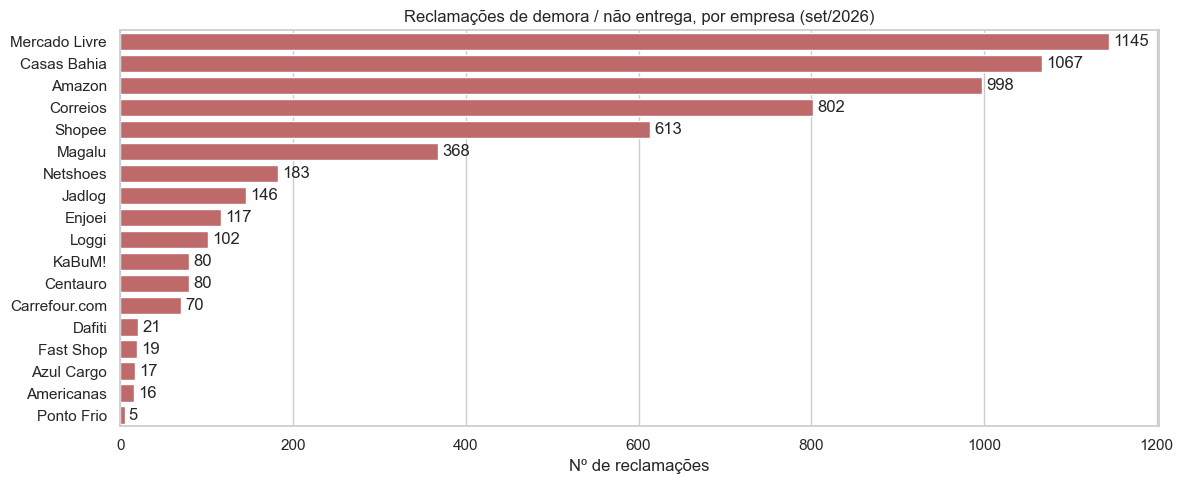

               total  demora  pct_demora
empresa                                 
Loggi            149     102        68.5
Correios        1275     802        62.9
Jadlog           270     146        54.1
Netshoes         482     183        38.0
Casas Bahia     3070    1067        34.8
Centauro         316      80        25.3
Amazon          4246     998        23.5
KaBuM!           354      80        22.6
Magalu          1647     368        22.3
Carrefour.com    319      70        21.9
Enjoei           534     117        21.9
Fast Shop         88      19        21.6
Dafiti           110      21        19.1
Shopee          4568     613        13.4
Mercado Livre   9488    1145        12.1
Americanas       183      16         8.7


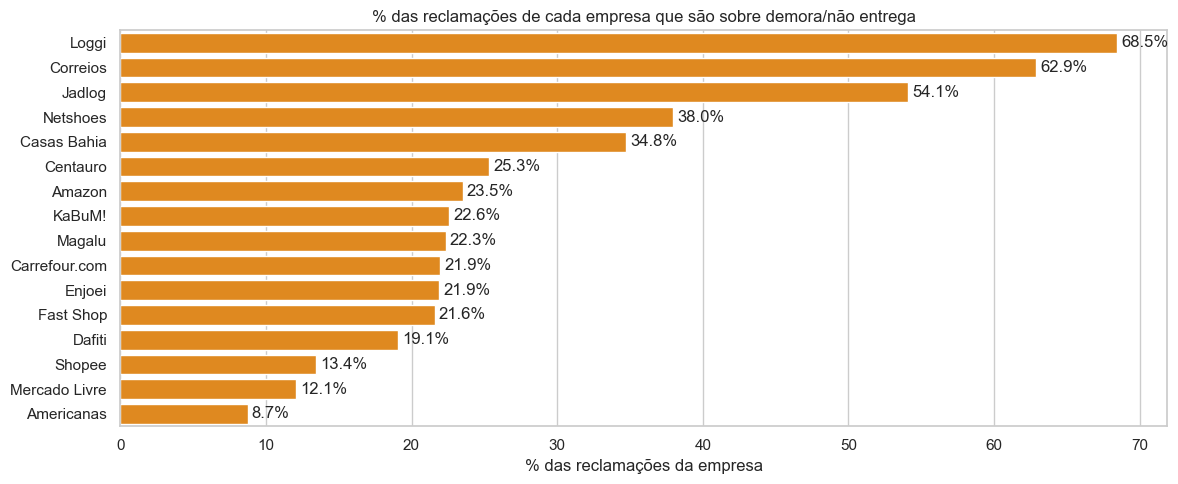

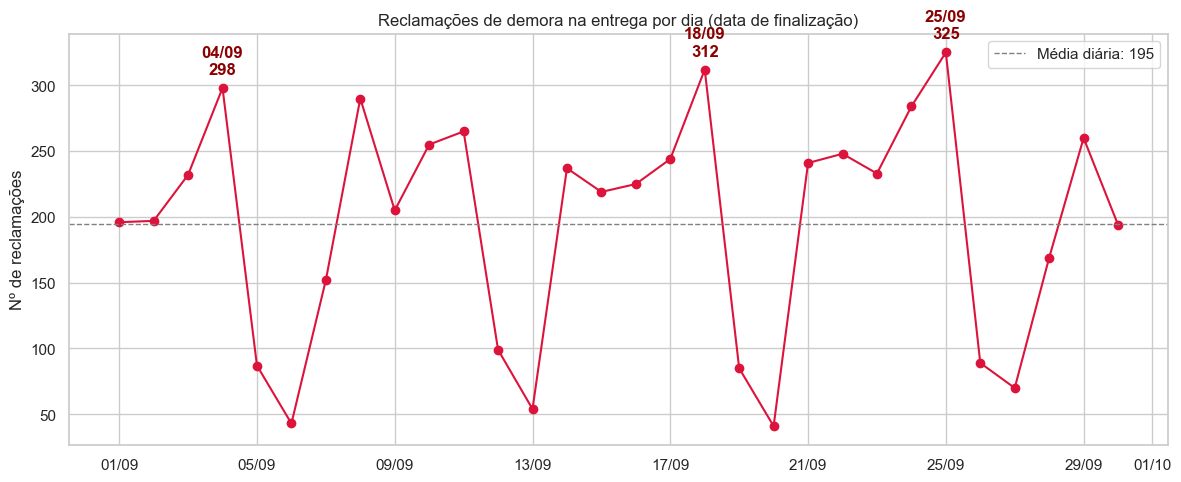


Datas de pico:
  25/09/2026 (Friday): 325 reclamações
  18/09/2026 (Friday): 312 reclamações
  04/09/2026 (Friday): 298 reclamações

Dia de pico de cada empresa (reclamações de demora):
  Mercado Livre      pico em 25/09/2026: 72 (média diária: 38.2)
  Casas Bahia        pico em 04/09/2026: 77 (média diária: 35.6)
  Amazon             pico em 18/09/2026: 70 (média diária: 33.3)
  Correios           pico em 25/09/2026: 49 (média diária: 26.7)
  Shopee             pico em 24/09/2026: 42 (média diária: 20.4)
  Magalu             pico em 25/09/2026: 31 (média diária: 12.3)
  Netshoes           pico em 08/09/2026: 13 (média diária: 7.0)
  Jadlog             pico em 18/09/2026: 13 (média diária: 5.0)

Os 10 dias com mais reclamações de demora somam 2,781 registros (47.5% do total do mês):
            reclamacoes    empresa_top  reclamacoes_empresa_top uf_top dia_semana  pct_empresa_top
data                                                                                              
2026-09

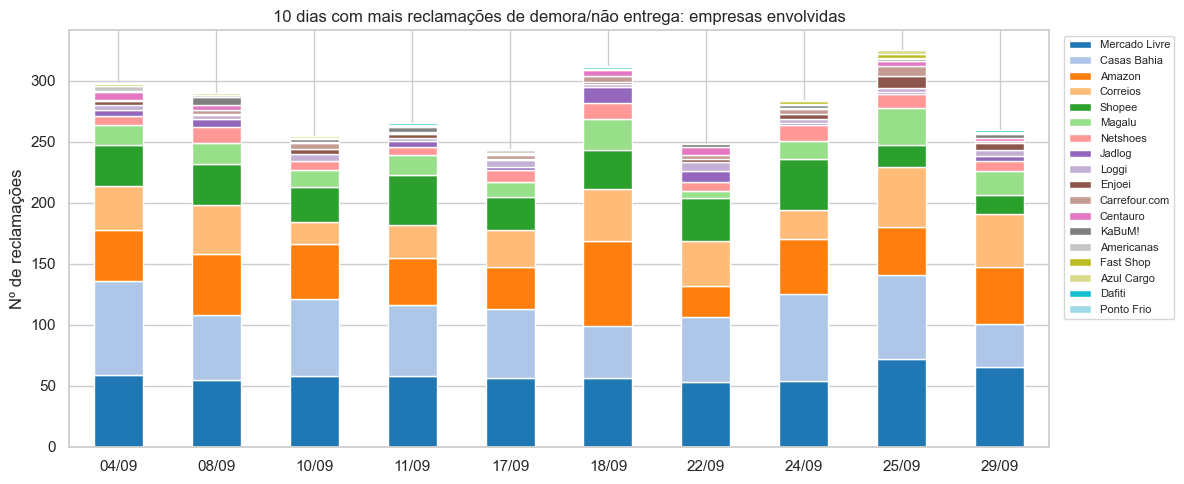


Amostra aleatória dos registros (5 por dia):
      data       empresa UF                  Cidade                                   Problema  Como Comprou Contratou Respondida                Situação  Tempo Resposta  Nota do Consumidor
2026-09-04      Correios RR               Boa Vista Não entrega / demora na entrega do produto                Internet          S     Finalizada avaliada             4.0                 3.0
2026-09-04      Netshoes PR                Curitiba Não entrega / demora na entrega do produto                Internet          S     Finalizada avaliada             7.0                 1.0
2026-09-04 Mercado Livre SP               São Paulo Não entrega / demora na entrega do produto                Internet          S     Finalizada avaliada             6.0                 5.0
2026-09-04        Amazon BA                Salvador Não entrega / demora na entrega do produto                Internet          S Finalizada não avaliada             8.0                 NaN
2026

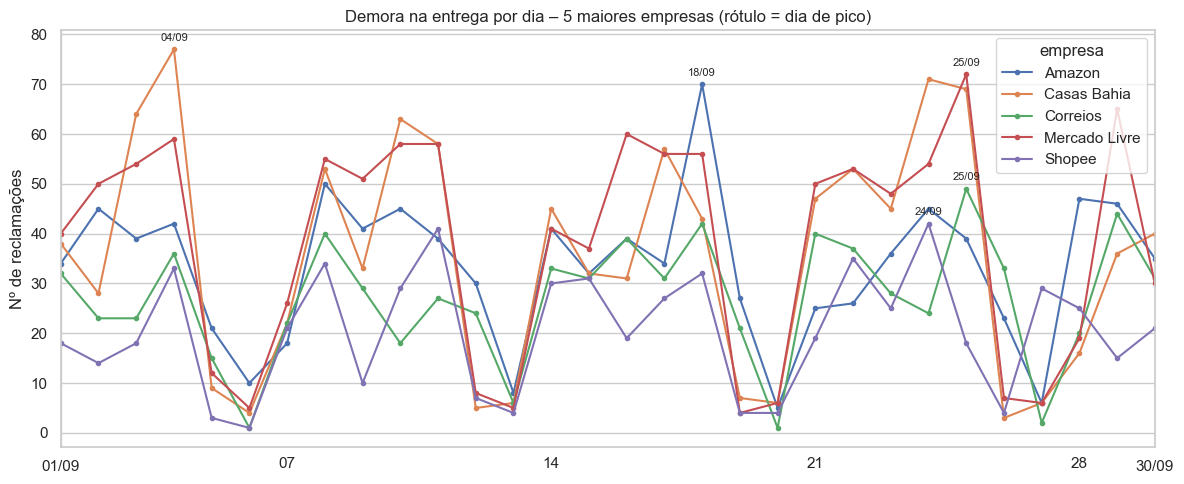

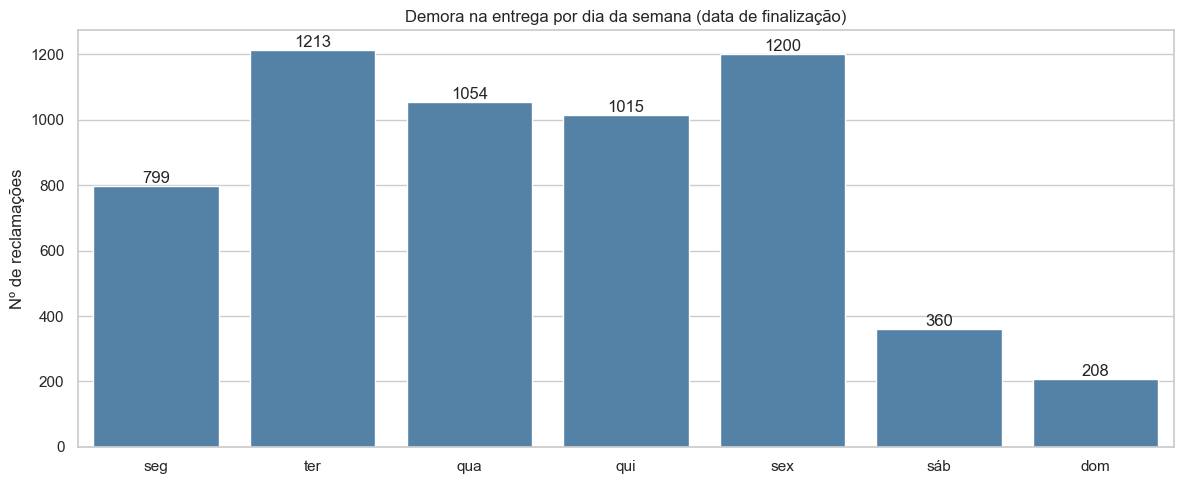

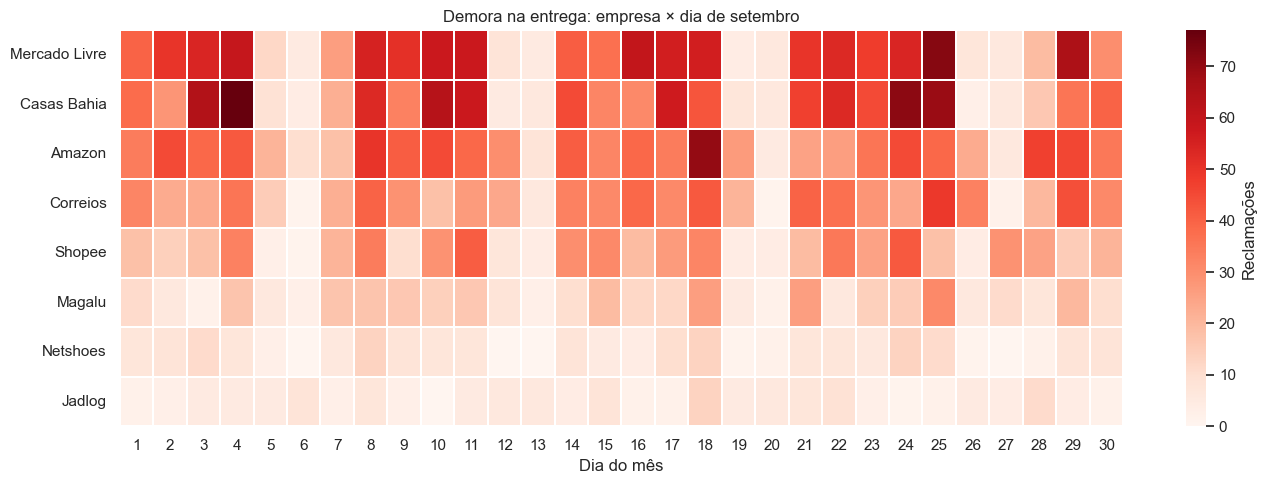


Resposta e satisfação (demora na entrega):
               reclamacoes  respondida_pct  tempo_resposta_dias  nota_consumidor  avaliadas
empresa                                                                                    
Mercado Livre         1145          100.00                 7.99             3.14        430
Casas Bahia           1067          100.00                 8.28             2.30        396
Amazon                 998           95.59                 6.59             2.70        423
Correios               802          100.00                 2.81             2.65        308
Shopee                 613           93.15                 9.00             2.29        224
Magalu                 368           70.11                 7.20             2.36        121
Netshoes               183           99.45                 8.21             3.20         70
Jadlog                 146            0.00                  NaN             1.17         35
Enjoei                 117          

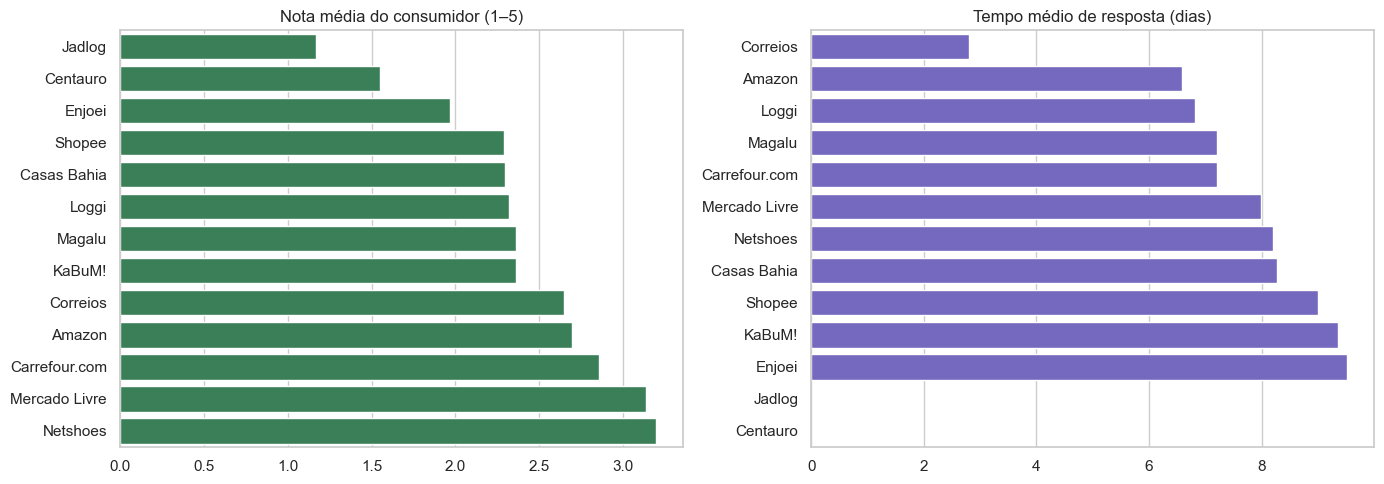

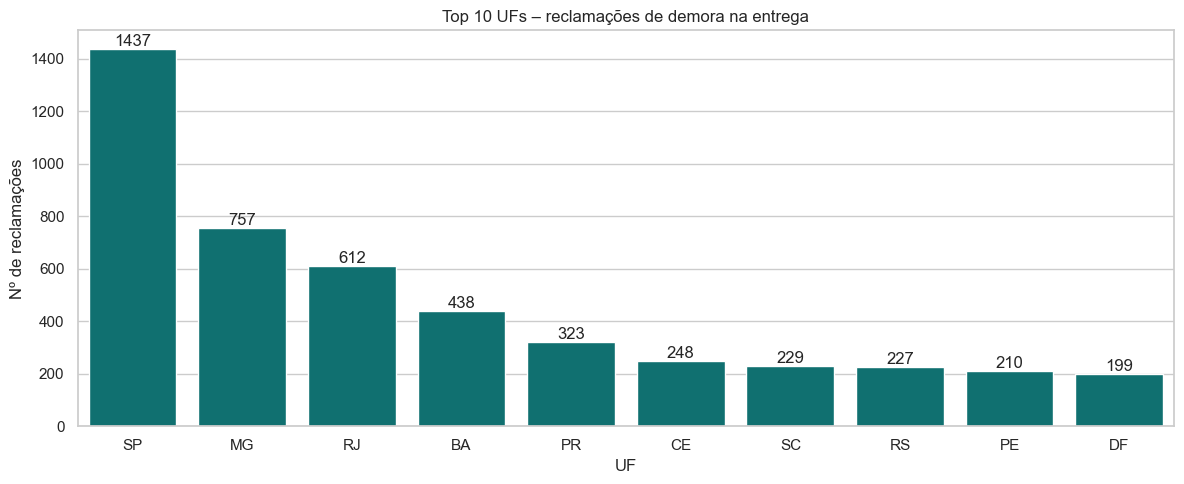

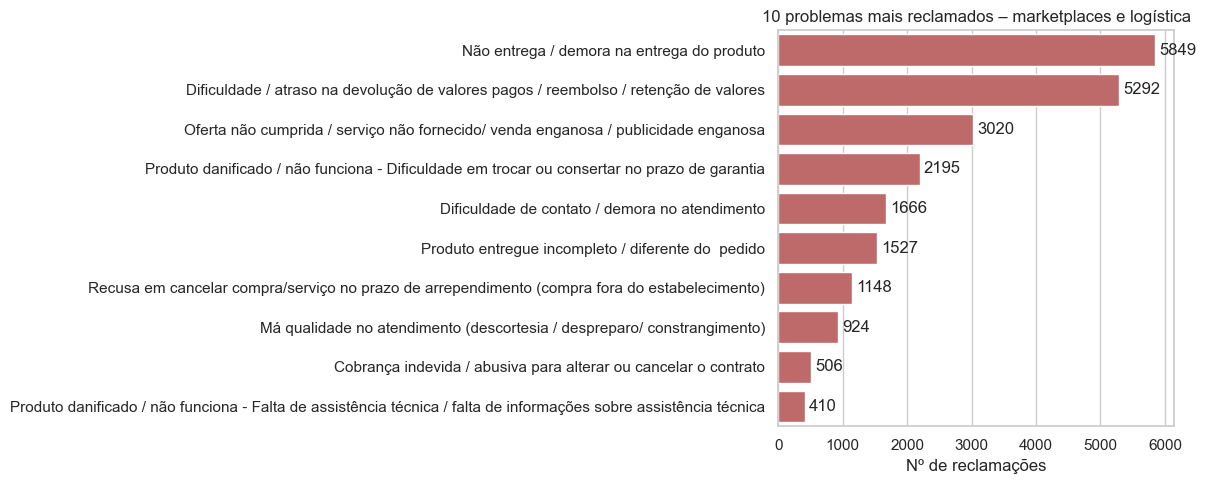

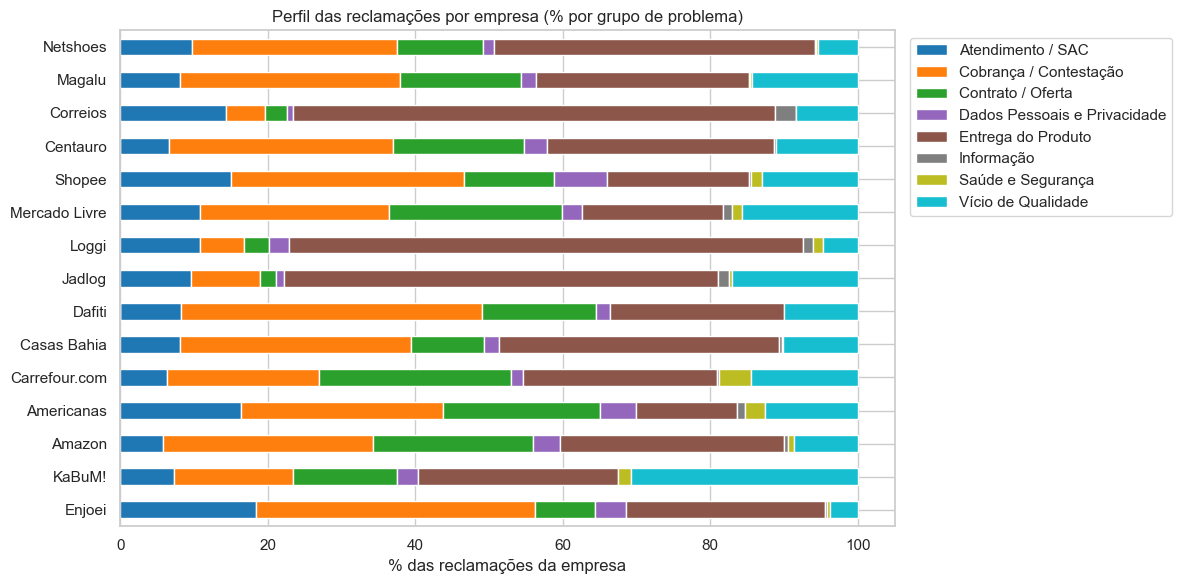


                             total  demora  entrega_geral  pct_demora  pct_grupo_entrega
tipo                                                                                   
Logística / Transportadora   1731    1067           1120        61.6               64.7
Marketplace / E-commerce    25443    4782           6345        18.8               24.9

Demora x outros problemas (mesmas empresas):
                    reclamacoes  respondida_pct  tempo_resposta  nota
categoria_problema                                                   
Demora/não entrega         5849           90.36            7.03  2.61
Outros problemas          21325           91.69            7.89  2.71


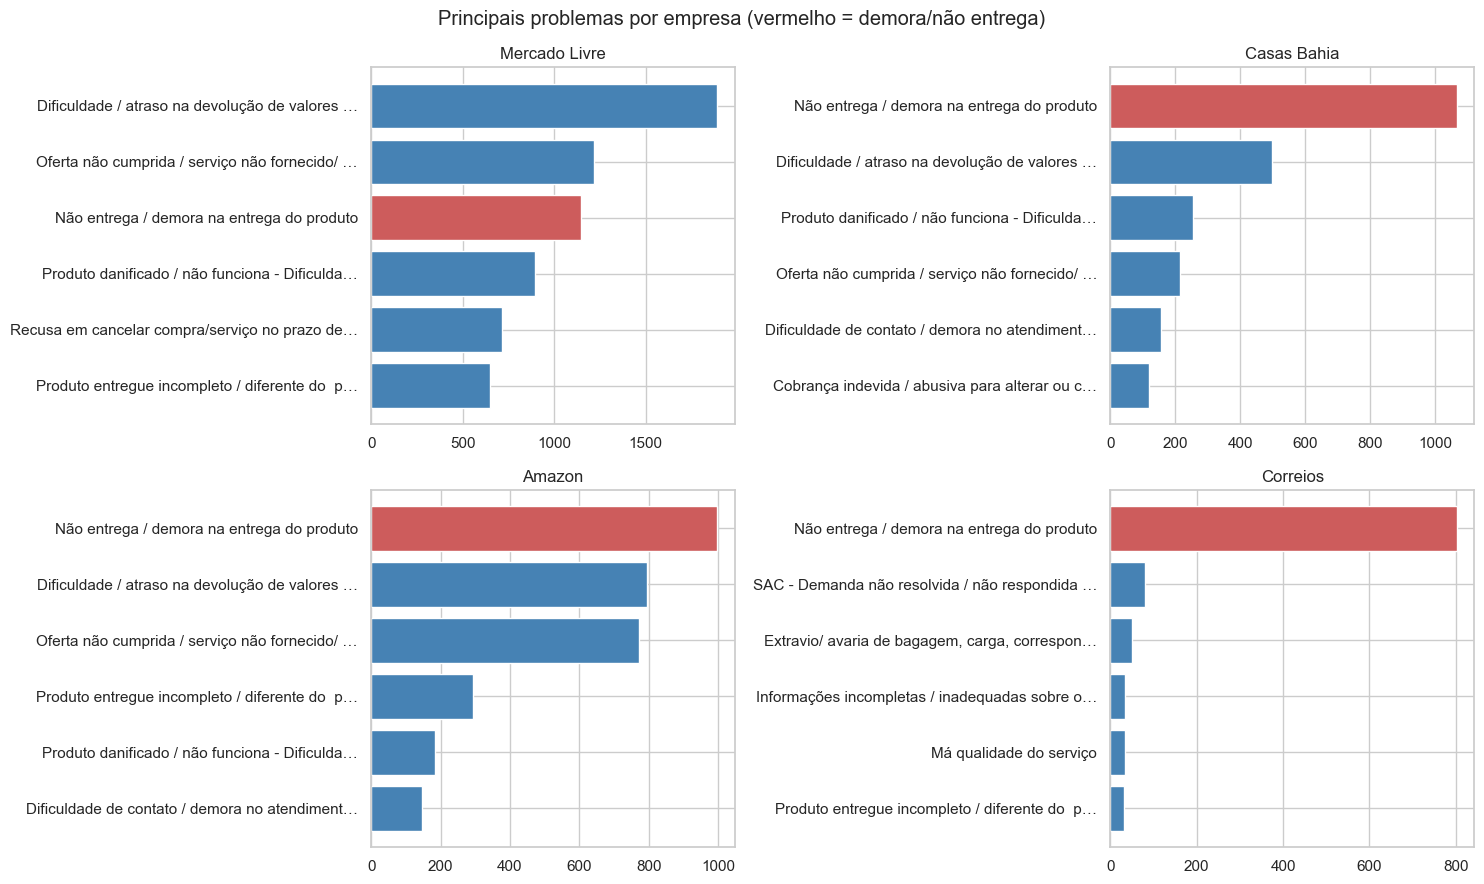

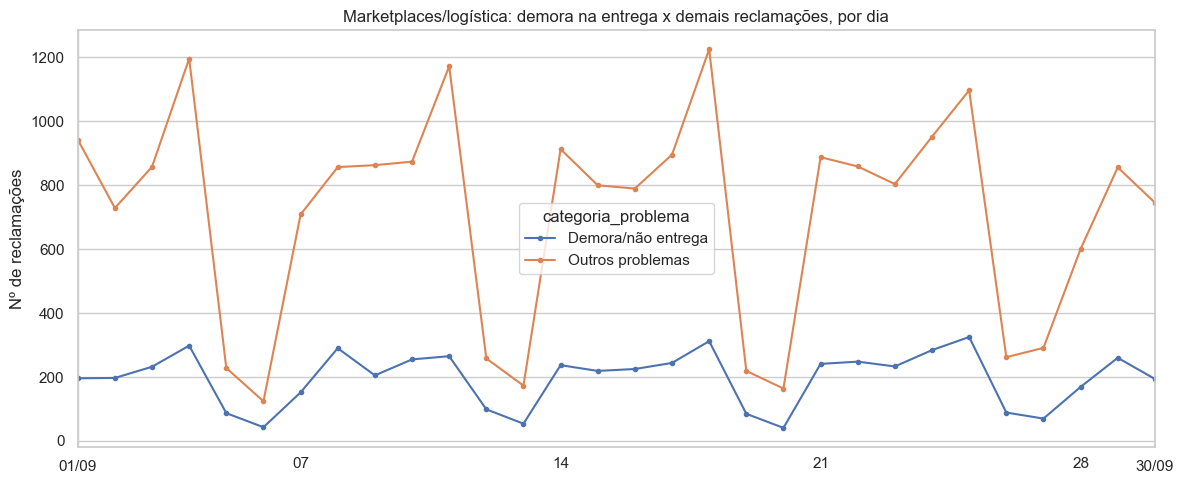


Correlação diária entre demora e demais reclamações: 0.96
Reclamações de demora/não entrega na cidade de São Paulo: 530

Top 10 dias em São Paulo (data de finalização):
            reclamacoes dia_semana empresa_mais_citada
dia                                                   
2026-09-25           34        sex         Casas Bahia
2026-09-18           31        sex              Amazon
2026-09-24           28        qui         Casas Bahia
2026-09-08           27        ter              Amazon
2026-09-09           25        qua              Amazon
2026-09-10           24        qui         Casas Bahia
2026-09-04           24        sex         Casas Bahia
2026-09-16           23        qua       Mercado Livre
2026-09-02           23        qua       Mercado Livre
2026-09-01           22        ter       Mercado Livre
2026-09-03           22        qui         Casas Bahia


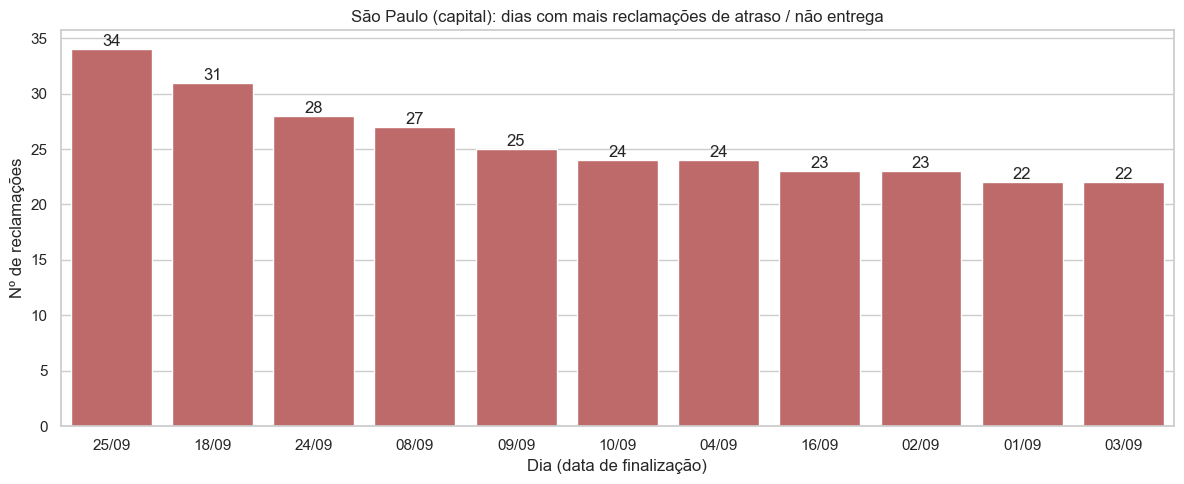

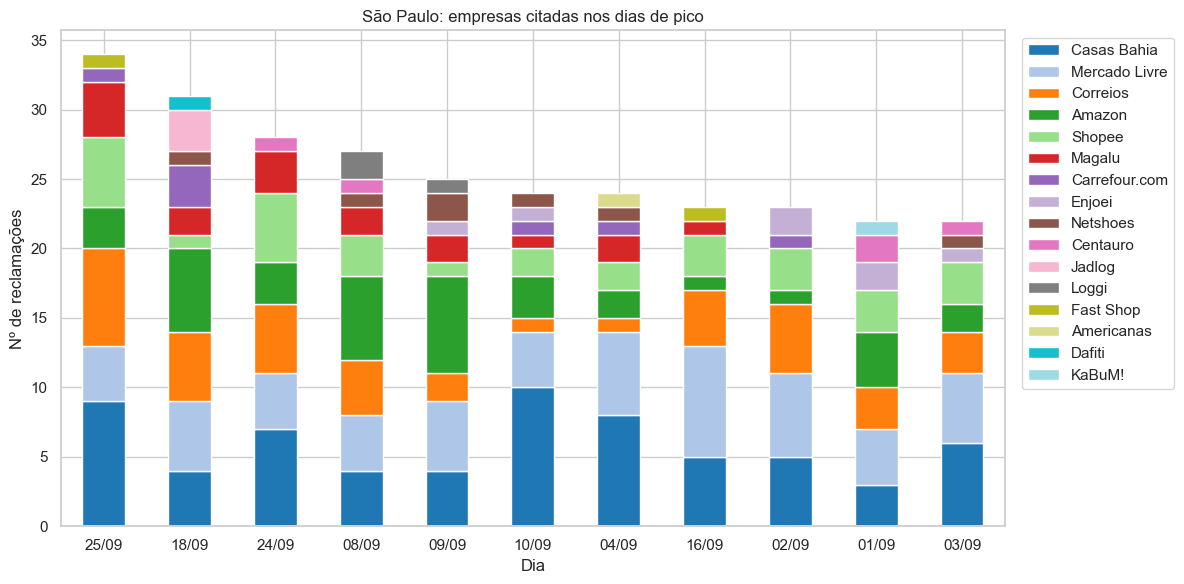


283 registros nos dias de pico. Exemplo (primeiros 15):
          data      empresa                                    Problema                                       Assunto Como Comprou Contratou        Faixa Etária Sexo Respondida  Tempo Resposta                 Situação  Nota do Consumidor
0   01/09/2026       Amazon  Não entrega / demora na entrega do produto  Acessórios e periféricos (monitor, impres...               Internet  entre 31 a 40 anos    M          S            10.0  Finalizada não avaliada                 NaN
1   01/09/2026       Amazon  Não entrega / demora na entrega do produto                     Microcomputador e laptops               Internet  entre 41 a 50 anos    M          S            10.0  Finalizada não avaliada                 NaN
2   01/09/2026       Amazon  Não entrega / demora na entrega do produto      Perfumaria, cosméticos e higiene pessoal               Internet  entre 31 a 40 anos    F          S             7.0      Finalizada avaliada            

In [14]:
# -*- coding: utf-8 -*-
"""
Reclamações finalizadas (Consumidor.gov.br) – Setembro/2026
Parte 1: marketplaces e empresas de logística + reclamações de demora na entrega
Parte 2: relação da demora na entrega com os demais problemas

ATENÇÃO: a coluna de data do arquivo é "Data Finalização" (dia em que a reclamação
foi encerrada), e não o dia em que o consumidor abriu a reclamação.

Cada bloco "# %%" funciona como uma célula no VS Code / Jupyter.
Dependências: pip install pandas matplotlib seaborn
"""

# %% 1. Importações e configuração
import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)

CAMINHO = "finalizadas_2026-09.csv"   # ajuste para o caminho do seu arquivo


def mostrar():
    """Exibe o gráfico e fecha a figura, para o próximo gráfico começar do zero."""
    plt.show()
    plt.close("all")


# %% 2. Leitura -> DataFrame (separador ';' e BOM no início do arquivo)
base_dir = Path.cwd().resolve()
CAMINHO = "finalizadas_2026-09.csv"

candidates = [
    Path(CAMINHO),
    base_dir / CAMINHO,
    base_dir.parent / CAMINHO,
    base_dir / "new_fontes" / CAMINHO,
    base_dir / "Analise-Climatica-Brasil" / "new_fontes" / CAMINHO,
    base_dir / ".." / "new_fontes" / CAMINHO,
]

for p in candidates:
    p = p.resolve()
    if p.exists():
        CAMINHO = str(p)
        break
else:
    matches = list(base_dir.rglob("finalizadas_2026-09.csv"))
    if matches:
        CAMINHO = str(matches[0])
    else:
        raise FileNotFoundError(
            "Arquivo 'finalizadas_2026-09.csv' não encontrado.\n"
            f"Diretório atual: {base_dir}\n"
            "Verifique se o arquivo está na pasta do projeto ou ajuste CAMINHO manualmente."
        )

df = pd.read_csv(CAMINHO, sep=";", encoding="utf-8-sig", low_memory=False)
df.columns = df.columns.str.strip()
print("Formato:", df.shape)
print(df.dtypes)

# %% 3. Limpeza
df["data"] = pd.to_datetime(df["Data Finalização"], errors="coerce")
df["dia_semana"] = df["data"].dt.dayofweek          # 0 = segunda
df["Região"] = df["Região"].str.strip()

# %% 4. Seleção de marketplaces e empresas de logística
# (regex no Nome Fantasia, nome padronizado, tipo). Há variações de nome no arquivo
# (ex.: "Casas Bahia" e "Casasbahia.com"), por isso a padronização.
EMPRESAS = [
    # --- marketplaces / e-commerce ---
    (r"mercado livre",                    "Mercado Livre",   "Marketplace / E-commerce"),
    (r"shopee brasil",                    "Shopee",          "Marketplace / E-commerce"),
    (r"amazon\.com",                      "Amazon",          "Marketplace / E-commerce"),
    (r"magazine luiza - loja online",     "Magalu",          "Marketplace / E-commerce"),
    (r"casas ?bahia(\.com)?$",            "Casas Bahia",     "Marketplace / E-commerce"),
    (r"americanas",                       "Americanas",      "Marketplace / E-commerce"),
    (r"netshoes",                         "Netshoes",        "Marketplace / E-commerce"),
    (r"kabum",                            "KaBuM!",          "Marketplace / E-commerce"),
    (r"carrefour\.com",                   "Carrefour.com",   "Marketplace / E-commerce"),
    (r"^centauro(\.com\.br)?$",           "Centauro",        "Marketplace / E-commerce"),
    (r"dafiti",                           "Dafiti",          "Marketplace / E-commerce"),
    (r"fast shop",                        "Fast Shop",       "Marketplace / E-commerce"),
    (r"ponto frio",                       "Ponto Frio",      "Marketplace / E-commerce"),
    (r"enjoei",                           "Enjoei",          "Marketplace / E-commerce"),
    (r"aliexpress|shein|temu",            "AliExpress/Shein/Temu", "Marketplace / E-commerce"),
    # --- logística / transportadoras ---
    (r"correios",                         "Correios",        "Logística / Transportadora"),
    (r"jadlog",                           "Jadlog",          "Logística / Transportadora"),
    (r"loggi",                            "Loggi",           "Logística / Transportadora"),
    (r"azul log",                         "Azul Cargo",      "Logística / Transportadora"),
    (r"kangu|total express|sequoia|j&t|jt express|mandaê", "Outras transportadoras", "Logística / Transportadora"),
]


def classifica(nome):
    nome = str(nome).strip().lower()
    for padrao, padrao_nome, tipo in EMPRESAS:
        if re.search(padrao, nome):
            return pd.Series([padrao_nome, tipo])
    return pd.Series([None, None])


# classifica só os nomes únicos (rápido) e depois junta ao DataFrame
nomes = pd.Series(df["Nome Fantasia"].dropna().unique())
mapa = nomes.to_frame("Nome Fantasia")
mapa[["empresa", "tipo"]] = mapa["Nome Fantasia"].apply(classifica)
df = df.merge(mapa, on="Nome Fantasia", how="left")

alvo = df.dropna(subset=["empresa"]).copy()
print(f"\nReclamações de marketplaces/logística: {len(alvo):,} de {len(df):,}")
print(alvo["empresa"].value_counts())

# %% 5. Definição de "demora na entrega"
# No arquivo, o problema se chama "Não entrega / demora na entrega do produto"
alvo["demora_entrega"] = alvo["Problema"].str.contains(
    "demora na entrega do produto", case=False, na=False
)
alvo["grupo_entrega"] = alvo["Grupo Problema"].eq("Entrega do Produto")  # inclui entrega errada/incompleta

print("\nReclamações de demora/não entrega:", alvo["demora_entrega"].sum())
print("Grupo 'Entrega do Produto' (inclui entregas erradas):", alvo["grupo_entrega"].sum())

entrega = alvo[alvo["demora_entrega"]].copy()

# =====================================================================
# PARTE 1 – FOCO EM DEMORA NA ENTREGA
# =====================================================================

# %% 6. Ranking: empresas com mais reclamações de demora na entrega
rank = entrega["empresa"].value_counts()
ax = sns.barplot(x=rank.values, y=rank.index, color="indianred")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_title("Reclamações de demora / não entrega, por empresa (set/2026)")
ax.set_xlabel("Nº de reclamações")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 7. Peso da demora dentro de cada empresa (% das reclamações da empresa)
tot = alvo.groupby("empresa").agg(total=("Problema", "size"), demora=("demora_entrega", "sum"))
tot["pct_demora"] = tot["demora"] / tot["total"] * 100
tot = tot[tot["total"] >= 50].sort_values("pct_demora", ascending=False)
print(tot.round(1))

ax = sns.barplot(x=tot["pct_demora"], y=tot.index, color="darkorange")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("% das reclamações de cada empresa que são sobre demora/não entrega")
ax.set_xlabel("% das reclamações da empresa")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 8. Evolução diária (total) com as datas de pico destacadas
diario = entrega.groupby("data").size()
media = diario.mean()
picos = diario.nlargest(3)

fig, ax = plt.subplots()
ax.plot(diario.index, diario.values, marker="o", color="crimson")
ax.axhline(media, color="gray", linestyle="--", linewidth=1, label=f"Média diária: {media:.0f}")
for dt, v in picos.items():
    ax.annotate(f"{dt:%d/%m}\n{v}", (dt, v), textcoords="offset points",
                xytext=(0, 10), ha="center", fontweight="bold", color="darkred")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Reclamações de demora na entrega por dia (data de finalização)")
ax.set_ylabel("Nº de reclamações")
ax.legend()
plt.tight_layout()
mostrar()

print("\nDatas de pico:")
for dt, v in picos.items():
    print(f"  {dt:%d/%m/%Y} ({dt:%A}): {v} reclamações")

# %% 9. Datas de pico por empresa
print("\nDia de pico de cada empresa (reclamações de demora):")
por_emp_dia = entrega.groupby(["empresa", "data"]).size()
for emp in rank.index[:8]:
    s = por_emp_dia[emp]
    print(f"  {emp:<18} pico em {s.idxmax():%d/%m/%Y}: {s.max()} (média diária: {s.mean():.1f})")

# %% 9B. Registros dos 10 dias com mais reclamações de demora / não entrega
top10_dias = diario.nlargest(10).sort_index()
registros = (entrega[entrega["data"].isin(top10_dias.index)]
             .sort_values(["data", "empresa"])
             [["data", "empresa", "tipo", "UF", "Cidade", "Problema", "Assunto",
               "Como Comprou Contratou", "Respondida", "Situação",
               "Tempo Resposta", "Nota do Consumidor"]]
             .reset_index(drop=True))

# 9B.1 Resumo dos 10 dias: total, dia da semana e empresa mais citada
resumo_dias = (registros.groupby("data")
               .agg(reclamacoes=("empresa", "size"),
                    empresa_top=("empresa", lambda s: s.value_counts().index[0]),
                    reclamacoes_empresa_top=("empresa", lambda s: s.value_counts().iloc[0]),
                    uf_top=("UF", lambda s: s.value_counts().index[0]))
               .assign(dia_semana=lambda t: t.index.day_name()))
resumo_dias["pct_empresa_top"] = (resumo_dias["reclamacoes_empresa_top"]
                                  / resumo_dias["reclamacoes"] * 100).round(1)
print(f"\nOs 10 dias com mais reclamações de demora somam {len(registros):,} registros "
      f"({len(registros) / len(entrega) * 100:.1f}% do total do mês):")
print(resumo_dias.sort_values("reclamacoes", ascending=False).to_string())

# 9B.2 Empresas em cada um desses dias (barras empilhadas)
dias_emp = (registros.groupby(["data", "empresa"]).size().unstack(fill_value=0))
dias_emp = dias_emp[dias_emp.sum().sort_values(ascending=False).index]
ax = dias_emp.plot(kind="bar", stacked=True, figsize=(12, 5), colormap="tab20")
ax.set_xticklabels([f"{d:%d/%m}" for d in dias_emp.index], rotation=0)
ax.set_title("10 dias com mais reclamações de demora/não entrega: empresas envolvidas")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
mostrar()

# 9B.3 Registros individuais (amostra na tela + arquivo completo em CSV)
pd.set_option("display.max_columns", None, "display.width", 250, "display.max_colwidth", 60)
print("\nAmostra aleatória dos registros (5 por dia):")
print(registros.groupby("data").sample(5, random_state=42)
      .drop(columns=["tipo", "Assunto"]).to_string(index=False))

registros.assign(data=registros["data"].dt.strftime("%d/%m/%Y")).to_csv(
    "registros_top10_dias_demora_entrega.csv", sep=";", index=False, encoding="utf-8-sig")
print(f"\nArquivo salvo: registros_top10_dias_demora_entrega.csv ({len(registros):,} linhas)")

# %% 10. Evolução diária das 5 maiores empresas
top5 = rank.head(5).index
pivot = (entrega[entrega["empresa"].isin(top5)]
         .groupby(["data", "empresa"]).size().unstack(fill_value=0))
ax = pivot.plot(marker="o", markersize=3)
for emp in pivot.columns:
    dt = pivot[emp].idxmax()
    ax.annotate(f"{dt:%d/%m}", (dt, pivot[emp].max()), textcoords="offset points",
                xytext=(0, 6), ha="center", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Demora na entrega por dia – 5 maiores empresas (rótulo = dia de pico)")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# %% 11. Padrão por dia da semana
nomes_dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
sem = entrega["dia_semana"].value_counts().sort_index()
ax = sns.barplot(x=[nomes_dias[i] for i in sem.index], y=sem.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("Demora na entrega por dia da semana (data de finalização)")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# %% 12. Mapa de calor: empresa x dia do mês
heat = (entrega[entrega["empresa"].isin(rank.head(8).index)]
        .assign(dia=lambda d: d["data"].dt.day)
        .groupby(["empresa", "dia"]).size().unstack(fill_value=0)
        .reindex(rank.head(8).index))
plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="Reds", linewidths=0.3, cbar_kws={"label": "Reclamações"})
plt.title("Demora na entrega: empresa × dia de setembro")
plt.xlabel("Dia do mês")
plt.ylabel("")
plt.tight_layout()
mostrar()

# %% 13. Resposta, prazo e satisfação (por empresa)
qual = (entrega.groupby("empresa")
        .agg(reclamacoes=("Problema", "size"),
             respondida_pct=("Respondida", lambda s: (s == "S").mean() * 100),
             tempo_resposta_dias=("Tempo Resposta", "mean"),
             nota_consumidor=("Nota do Consumidor", "mean"),
             avaliadas=("Nota do Consumidor", "count"))
        .sort_values("reclamacoes", ascending=False)
        .round(2))
print("\nResposta e satisfação (demora na entrega):")
print(qual)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
q = qual[qual["reclamacoes"] >= 30].sort_values("nota_consumidor")
sns.barplot(x=q["nota_consumidor"], y=q.index, color="seagreen", ax=axes[0])
axes[0].set_title("Nota média do consumidor (1–5)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
q2 = qual[qual["reclamacoes"] >= 30].sort_values("tempo_resposta_dias")
sns.barplot(x=q2["tempo_resposta_dias"], y=q2.index, color="slateblue", ax=axes[1])
axes[1].set_title("Tempo médio de resposta (dias)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
mostrar()

# %% 14. UFs com mais reclamações de demora
uf = entrega["UF"].value_counts().head(10)
ax = sns.barplot(x=uf.index, y=uf.values, color="teal")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("Top 10 UFs – reclamações de demora na entrega")
ax.set_xlabel("UF")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# =====================================================================
# PARTE 2 – RELAÇÃO DA DEMORA COM OS DEMAIS PROBLEMAS
# =====================================================================

# %% 15. Principais problemas das mesmas empresas (demora x outros)
top_prob = alvo["Problema"].value_counts().head(10)
ax = sns.barplot(x=top_prob.values, y=top_prob.index, color="indianred")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_title("10 problemas mais reclamados – marketplaces e logística")
ax.set_xlabel("Nº de reclamações")
ax.set_ylabel("")
plt.tight_layout()
mostrar()

# %% 16. Mix de problemas por empresa (Grupo Problema, % dentro de cada empresa)
maiores = alvo["empresa"].value_counts()
maiores = maiores[maiores >= 100].index
mix = (pd.crosstab(alvo[alvo["empresa"].isin(maiores)]["empresa"],
                   alvo[alvo["empresa"].isin(maiores)]["Grupo Problema"],
                   normalize="index") * 100)
mix = mix.loc[mix.sum(axis=1).sort_values().index]
mix.plot(kind="barh", stacked=True, figsize=(12, 6), colormap="tab10")
plt.title("Perfil das reclamações por empresa (% por grupo de problema)")
plt.xlabel("% das reclamações da empresa")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
mostrar()

# %% 17. Demora na entrega x tipo de empresa (marketplace x logística)
por_tipo = (alvo.groupby("tipo")
            .agg(total=("Problema", "size"), demora=("demora_entrega", "sum"),
                 entrega_geral=("grupo_entrega", "sum")))
por_tipo["pct_demora"] = por_tipo["demora"] / por_tipo["total"] * 100
por_tipo["pct_grupo_entrega"] = por_tipo["entrega_geral"] / por_tipo["total"] * 100
print("\n", por_tipo.round(1))

# %% 18. Demora x outros problemas: satisfação e resposta
alvo["categoria_problema"] = alvo["demora_entrega"].map(
    {True: "Demora/não entrega", False: "Outros problemas"})
cmp = (alvo.groupby("categoria_problema")
       .agg(reclamacoes=("Problema", "size"),
            respondida_pct=("Respondida", lambda s: (s == "S").mean() * 100),
            tempo_resposta=("Tempo Resposta", "mean"),
            nota=("Nota do Consumidor", "mean"))
       .round(2))
print("\nDemora x outros problemas (mesmas empresas):")
print(cmp)

# %% 19. Quais problemas aparecem junto da demora, nas empresas mais afetadas?
# Para cada empresa: top 5 problemas, destacando a demora
top_emp = rank.head(4).index
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, emp in zip(axes.ravel(), top_emp):
    s = (alvo[alvo["empresa"] == emp]["Problema"].value_counts().head(6))
    s.index = [i[:45] + "…" if len(i) > 45 else i for i in s.index]
    cores = ["indianred" if "demora na entrega" in i.lower() else "steelblue" for i in s.index]
    ax.barh(s.index[::-1], s.values[::-1], color=cores[::-1])
    ax.set_title(emp)
plt.suptitle("Principais problemas por empresa (vermelho = demora/não entrega)")
plt.tight_layout()
mostrar()

# %% 20. Evolução diária: demora x todas as demais reclamações
diario_geral = alvo.groupby(["data", "categoria_problema"]).size().unstack(fill_value=0)
ax = diario_geral.plot(marker="o", markersize=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Marketplaces/logística: demora na entrega x demais reclamações, por dia")
ax.set_xlabel("")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()
print("\nCorrelação diária entre demora e demais reclamações:",
      round(diario_geral.corr().iloc[0, 1], 2))


# =====================================================================
# PARTE 3 – CIDADE DE SÃO PAULO: REGISTROS DOS 10 DIAS COM MAIS ATRASOS / NÃO ENTREGAS
# =====================================================================

# %% 21. Filtro: cidade de São Paulo (SP) + demora/não entrega
# Usa a mesma base da Parte 1 (marketplaces e logística). Para considerar TODAS as
# empresas do arquivo, troque `entrega` por: df[df["Problema"].str.contains(
# "demora na entrega do produto", case=False, na=False)]
TOP_DIAS = 10

sp = entrega[
    entrega["Cidade"].str.strip().str.lower().eq("são paulo")
    & entrega["UF"].str.strip().eq("SP")
].copy()
sp["dia"] = sp["data"].dt.date
print(f"Reclamações de demora/não entrega na cidade de São Paulo: {len(sp)}")

# %% 22. Os 10 dias com mais reclamações (inclui empates no 10º lugar)
ranking_dias = sp.groupby("dia").size().sort_values(ascending=False)
corte = ranking_dias.nlargest(TOP_DIAS).min()
dias_top = ranking_dias[ranking_dias >= corte].index

resumo_dias = (ranking_dias[ranking_dias.index.isin(dias_top)]
               .rename("reclamacoes").to_frame())
resumo_dias["dia_semana"] = [nomes_dias[pd.Timestamp(d).dayofweek] for d in resumo_dias.index]
resumo_dias["empresa_mais_citada"] = [
    sp[sp["dia"] == d]["empresa"].value_counts().idxmax() for d in resumo_dias.index
]
print(f"\nTop {TOP_DIAS} dias em São Paulo (data de finalização):")
print(resumo_dias)

ax = sns.barplot(x=[f"{pd.Timestamp(d):%d/%m}" for d in resumo_dias.index],
                 y=resumo_dias["reclamacoes"], color="indianred")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_title("São Paulo (capital): dias com mais reclamações de atraso / não entrega")
ax.set_xlabel("Dia (data de finalização)")
ax.set_ylabel("Nº de reclamações")
plt.tight_layout()
mostrar()

# %% 23. Empresas em cada um desses dias
por_empresa_dia = (sp[sp["dia"].isin(dias_top)]
                   .groupby(["dia", "empresa"]).size().unstack(fill_value=0)
                   .loc[resumo_dias.index])
por_empresa_dia = por_empresa_dia[por_empresa_dia.sum().sort_values(ascending=False).index]
por_empresa_dia.index = [f"{pd.Timestamp(d):%d/%m}" for d in por_empresa_dia.index]
por_empresa_dia.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab20")
plt.title("São Paulo: empresas citadas nos dias de pico")
plt.xlabel("Dia")
plt.ylabel("Nº de reclamações")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
mostrar()

# %% 24. Registros (linha a linha) dos 10 dias de pico
colunas = ["data", "empresa", "Problema", "Assunto", "Como Comprou Contratou",
           "Faixa Etária", "Sexo", "Respondida", "Tempo Resposta",
           "Situação", "Nota do Consumidor"]
registros = (sp[sp["dia"].isin(dias_top)]
             .sort_values(["data", "empresa"])[colunas]
             .reset_index(drop=True))
registros["data"] = registros["data"].dt.strftime("%d/%m/%Y")

print(f"\n{len(registros)} registros nos dias de pico. Exemplo (primeiros 15):")
with pd.option_context("display.max_columns", None, "display.width", 250,
                       "display.max_colwidth", 45):
    print(registros.head(15))

# salva todos os registros em CSV (abre direto no Excel: sep=';' e BOM)
registros.to_csv("ocorrencias_atraso_sp_top10_dias.csv", sep=";",
                 index=False, encoding="utf-8-sig")
print("\nArquivo salvo: ocorrencias_atraso_sp_top10_dias.csv")

# %% 25. Para ver um dia específico (troque a data)
dia_escolhido = "2026-09-25"
print(registros[registros["data"] == pd.Timestamp(dia_escolhido).strftime("%d/%m/%Y")]
      .to_string(max_colwidth=45))